# Notebook 02: Data Preparation for Spatial Analysis

## Objective

This notebook prepares the harmonized potato Combined Evaluation Trial (CET) dataset for spatial statistical analysis.

The specific objectives are to:

* Load the harmonized master dataset generated in Notebook 01.
* Verify the integrity of the experimental design variables.
* Standardize data types required for spatial modelling.
* Create trial-specific datasets for each testing environment.
* Explore field layouts and trial structure.
* Audit quantitative traits for completeness and suitability for analysis.
* Generate modelling-ready datasets for subsequent spatial adjustment using SpATS.

## Input

`data/processed/master_raw.csv`

## Output

* `data/processed/analysis_ready.csv`
* Trial-specific datasets
* Trial summary tables
* Trait audit tables
* Field layout visualizations
* Modelling-ready datasets for spatial analysis

## Background

The dataset comprises six potato Combined Evaluation Trials (CETs) conducted across three locations under two trial series:

* **EA21**
* **LBHT**

The **KE25NJO-EA21-AT01** trial differs structurally from the Molo and UON EA21 trials because harvest-related variables were recorded within the phenotype worksheet, whereas the other EA21 trials stored harvest measurements in separate yield worksheets.

These structural differences were harmonized in Notebook 01 to produce a unified master dataset (`master_raw.csv`). This notebook prepares the harmonized dataset for spatial statistical modelling by generating trial-specific datasets and performing exploratory quality assessment prior to model fitting.


In [1]:
from pathlib import Path

PROJECT_DIR = Path.home() / "Potato_CET_MultiEnvironment"

DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
HARMONIZED_DIR = DATA_DIR / "harmonized"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR = OUTPUT_DIR / "tables"

print(f"Project root: {PROJECT_DIR}")
print(f"Processed dir exists: {PROCESSED_DIR.exists()}")

Project root: /home/nosin/Potato_CET_MultiEnvironment
Processed dir exists: True


In [2]:
# ==========================================================
# Importing libraries
# ==========================================================

import pandas as pd
import numpy as np
import pickle

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)

In [3]:
# ==========================================================
# Loading master dataset
# ==========================================================

import pandas as pd

master = pd.read_csv(PROCESSED_DIR / "master_raw.csv"
)

print("="*60)
print("MASTER DATASET LOADED")
print("="*60)

print(f"Rows    : {master.shape[0]}")
print(f"Columns : {master.shape[1]}")
print(f"Trials  : {master['trial'].nunique()}")

print("\nTrials included:")

for t in sorted(master["trial"].unique()):
    print(" •", t)

MASTER DATASET LOADED
Rows    : 1320
Columns : 119
Trials  : 6

Trials included:
 • KE25MOL-EA21-AT01_table-Final
 • KE25MOL-LBHT-IT01_table-Final
 • KE25NJO-EA21-AT01_table-Final
 • KE25NJO-LBHT-IT01_table-Final
 • KE25UON-EA21-AT01_table-Final
 • KE25UON-LBHT-IT01_table-Final


In [4]:
# ==========================================================
# Dataset overview
# ==========================================================

print("="*60)
print("DATASET DIMENSIONS")
print("="*60)

display(master.shape)

print("\n")
print("="*60)
print("COLUMN NAMES")
print("="*60)

display(master.columns.tolist())

DATASET DIMENSIONS


(1320, 119)



COLUMN NAMES


['plot',
 'geno',
 'entry',
 'row',
 'column',
 'rep',
 'ntp',
 'npe',
 'growth_speed',
 'pgh',
 'plant_unif',
 'plant_vigor',
 'flowering',
 'flowering_date',
 'flower_colour',
 'overall_impression',
 'se',
 'tuber_apper',
 'tub_unif',
 'tub_size',
 'skin_colour',
 'flesh_colour',
 'late_blight_60_days',
 'late_blight_90_days',
 'notes',
 'notes2',
 'selected_clone',
 'name',
 'comment',
 '0_10',
 '0_10_1',
 'weight_g_0_10',
 'weight_0_10',
 'average_length_mm_0_10',
 '10_30',
 '10_30_1',
 'weight_g_10_30',
 'weight_10_30',
 'average_length_mm_10_30',
 'average_length_mm_10',
 '30_35',
 '30_35_1',
 'weight_g_30_35',
 'weight_30_35',
 'average_length_mm_30_35',
 'average_length_mm_30',
 '35_40',
 '35_40_1',
 'weight_g_35_40',
 'weight_35_40',
 'average_length_mm_35_40',
 'average_length_mm_35',
 '40_45',
 '40_45_1',
 'weight_g_40_45',
 'weight_40_45',
 'average_length_mm_40_45',
 'average_length_mm_40',
 '45_50',
 '45_50_1',
 'weight_g_45_50',
 'weight_45_50',
 'average_length_mm_45_50

In [5]:
# ==========================================================
# Data types
# ==========================================================

master.info()

<class 'pandas.DataFrame'>
RangeIndex: 1320 entries, 0 to 1319
Columns: 119 entries, plot to selected_clones
dtypes: float64(96), int64(5), str(18)
memory usage: 1.2 MB


In [6]:
# ==========================================================
# First observations
# ==========================================================

master.head()

,plot,geno,entry,row,column,rep,ntp,npe,growth_speed,pgh,plant_unif,plant_vigor,flowering,flowering_date,flower_colour,overall_impression,se,tuber_apper,tub_unif,tub_size,skin_colour,flesh_colour,late_blight_60_days,late_blight_90_days,notes,notes2,selected_clone,name,comment,0_10,0_10_1,weight_g_0_10,weight_0_10,average_length_mm_0_10,10_30,10_30_1,weight_g_10_30,weight_10_30,average_length_mm_10_30,average_length_mm_10,30_35,30_35_1,weight_g_30_35,weight_30_35,average_length_mm_30_35,average_length_mm_30,35_40,35_40_1,weight_g_35_40,weight_35_40,average_length_mm_35_40,average_length_mm_35,40_45,40_45_1,weight_g_40_45,weight_40_45,average_length_mm_40_45,average_length_mm_40,45_50,45_50_1,weight_g_45_50,weight_45_50,average_length_mm_45_50,average_length_mm_45,50_55,50_55_1,weight_g_50_55,weight_50_55,average_length_mm_50_55,average_length_mm_50,55_60,55_60_1,weight_g_55_60,weight_55_60,average_length_mm_55_60,average_length_mm_55,60_65,60_65_1,weight_g_60_65,weight_60_65,average_length_mm_60_65,average_length_mm_60,65_70,65_70_1,weight_g_65_70,weight_65_70,average_length_mm_65_70,average_length_mm_65,70,70_1,weight_g_70,weight_70,average_length_mm_70,total,weight_g_total,owg_g_total,owg_g_5kg_total,average_length_mm_total,average_nir_value_total,trial,location,population,total_weight_in_kgs,weight_in_air_kgs,weight_in_water_kgs,dm,late_blight_50_days,notes_1,photo_1,wilted,rotten_tubers,selected_and_non_selected,nph,late_blight_70_days,late_blight_80_days,photo,selected,tubers_shape,selected_clones
0,KE25MOL-EA21-AT01-00001,CIP3217004.022,10,1,1,1,20.0,20,5.0,2.0,7.0,9.0,3.0,2025-07-18 00:00:00,Purple,8.0,7.0,7.0,7.0,7.0,Light red,creme,NaN,5.0,NaN,"red eyes, nice tubers,",Selected,1.0,1.0,0.0,0.0,0.0,0.0,NaN,11.0,5.7,120.2,0.6,33.3,75.8,15.0,7.8,396.3,1.9,46.4,78.4,12.0,6.2,498.4,2.4,54.4,81.3,24.0,12.4,1458.3,7.1,63.7,83.4,28.0,14.5,2365.6,11.6,71.1,87.0,48.0,24.9,5694.9,27.9,85.5,91.3,32.0,16.6,5096.9,25.0,93.4,96.3,18.0,9.3,3658.1,17.9,100.8,100.3,5.0,2.6,1135.4,5.6,98.6,98.6,0.0,0.0,0.0,0.0,NaN,193.0,20423.7,0.0,0.0,75.8,148.7,KE25MOL-EA21-AT01_table-Final,Molo,EA21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,KE25MOL-EA21-AT01-00002,CIP3177023.046,3,2,1,1,20.0,7,3.0,2.0,5.0,3.0,3.0,2024-07-22 00:00:00,White,4.0,3.0,5.0,7.0,5.0,Yellow,yellow,0.0,0.0,small plants,few tubers,Not Selected,2.0,2.0,0.0,0.0,0.0,0.0,NaN,2.0,14.3,20.8,2.8,31.0,57.6,1.0,7.1,17.6,2.3,38.8,62.1,0.0,0.0,0.0,0.0,NaN,64.2,4.0,28.6,202.1,26.8,56.3,64.2,7.0,50.0,513.4,68.1,68.7,68.7,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,14.0,753.9,0.0,0.0,57.6,145.7,KE25MOL-EA21-AT01_table-Final,Molo,EA21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,KE25MOL-EA21-AT01-00003,CIP3217016.038,47,3,1,1,20.0,15,5.0,2.0,5.0,5.0,0.0,NaN,NaN,5.0,5.0,7.0,5.0,7.0,Red,yellow,0.0,0.0,NaN,"few tubers, unica like",Not Selected,3.0,3.0,0.0,0.0,0.0,0.0,NaN,5.0,9.6,49.8,1.0,32.4,77.5,5.0,9.6,117.1,2.3,45.1,82.3,5.0,9.6,198.1,3.8,56.0,86.7,8.0,15.4,465.3,9.0,65.6,90.9,10.0,19.2,925.7,17.9,80.4,97.9,8.0,15.4,1021.7,19.8,98.9,107.1,4.0,7.7,681.1,13.2,108.6,113.0,3.0,5.8,618.8,12.0,106.6,115.5,4.0,7.7,1093.5,21.1,122.2,122.2,0.0,0.0,0.0,0.0,NaN,52.0,5171.8,0.0,0.0,77.5,148.7,KE25MOL-EA21-AT01_table-Final,Molo,EA21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,KE25MOL-EA21-AT01-00004,CIP3217016.076,48,4,1,1,20.0,17,5.0,2.0,7.0,7.0,5.0,2024-07-08 00:00:00,White,6.0,5.0,5.0,5.0,5.0,Yellow,light yellow,10.0,70.0,NaN,long oval tubers,Not Selected,4.0,4.0,0.0,0.0,0.0,0.0,NaN,11.0,15.9,170.6,3.6,43.9,76.6,12.0,17.4,384.6,8.0,57.7,82.8,15.0,21.7,903.2,18.9,77.5,89.4,14.0,20.3,1127.6,23.5,84.8,95.1,10.0,14.5,1080.9,22.6,98.7,103.6,6.0,8.7,917.2,19.2,109.3,110.6,1.0,1.4,205.0,4.3,118.8,118.8,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,69.0,4789.0,0.0,0.0,76.6,153.4,KE25MOL-EA21-AT01_table-Final,Molo,EA21,NaN,NaN,NaN,NaN,NaN,NaN

In [7]:
# ==========================================================
# Summary statistics
# ==========================================================

master.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
plot,1320,1320,KE25MOL-EA21-AT01-00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
geno,1320,191,Shangi,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
entry,1320.0,NaN,NaN,NaN,51.836364,36.187665,1.0,22.75,44.5,77.25,132.0
row,1320.0,NaN,NaN,NaN,14.886364,9.53796,1.0,7.0,14.0,21.0,44.0
column,1320.0,NaN,NaN,NaN,4.704545,2.760983,1.0,2.0,4.0,6.0,11.0
...,...,...,...,...,...,...,...,...,...,...,...
late_blight_80_days,433.0,NaN,NaN,NaN,5.311778,7.301844,0.0,0.0,5.0,10.0,45.0
photo,34,23,low yield,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
selected,438,3,No,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tubers_shape,43,9,4,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Variable Preparation

In [8]:
# ==========================================================
# Convert variables to appropriate data types
# ==========================================================

master["trial"] = master["trial"].astype("category")
master["geno"] = master["geno"].astype("category")

master["row"] = pd.to_numeric(master["row"])
master["column"] = pd.to_numeric(master["column"])

if "plot" in master.columns:
    master["plot"] = pd.to_numeric(master["plot"], errors="coerce").astype("Int64")

print(master.dtypes.head(10))

plot               Int64
geno            category
entry              int64
row                int64
column             int64
rep                int64
ntp              float64
npe                int64
growth_speed     float64
pgh              float64
dtype: object


# Verification of Experimental Design

In [9]:
# ==========================================================
# Verify experimental design variables
# ==========================================================

required = [
    "trial",
    "geno",
    "plot",
    "row",
    "column"
]

master[required].head()

,trial,geno,plot,row,column
0,KE25MOL-EA21-AT01_table-Final,CIP3217004.022,<NA>,1,1
1,KE25MOL-EA21-AT01_table-Final,CIP3177023.046,<NA>,2,1
2,KE25MOL-EA21-AT01_table-Final,CIP3217016.038,<NA>,3,1
3,KE25MOL-EA21-AT01_table-Final,CIP3217016.076,<NA>,4,1
4,KE25MOL-EA21-AT01_table-Final,CIP3217006.008,<NA>,5,1


In [10]:
# ==========================================================
# Check for missing values in design variables
# ==========================================================

master[required].isnull().sum()

trial        0
geno         0
plot      1320
row          0
column       0
dtype: int64

In [11]:
# ==========================================================
# Unique trials
# ==========================================================

master["trial"].value_counts()

trial
KE25MOL-LBHT-IT01_table-Final    264
KE25NJO-LBHT-IT01_table-Final    264
KE25UON-LBHT-IT01_table-Final    264
KE25UON-EA21-AT01_table-Final    180
KE25MOL-EA21-AT01_table-Final    174
KE25NJO-EA21-AT01_table-Final    174
Name: count, dtype: int64

In [12]:
# ==========================================================
# Number of unique genotypes
# ==========================================================

print(master["geno"].nunique())

191


In [13]:
# ==========================================================
# Row and column ranges
# ==========================================================

master.groupby("trial")[["row", "column"]].agg(["min", "max", "nunique"])

row             column            
                              min max nunique    min max nunique
trial                                                           
KE25MOL-EA21-AT01_table-Final   1  29      29      1   6       6
KE25MOL-LBHT-IT01_table-Final   1  24      24      1  11      11
KE25NJO-EA21-AT01_table-Final   1  29      29      1   6       6
KE25NJO-LBHT-IT01_table-Final   1  44      44      1   6       6
KE25UON-EA21-AT01_table-Final   1  20      20      1   9       9
KE25UON-LBHT-IT01_table-Final   1  24      24      1  11      11

# 8. Create Trial-Specific Datasets

The harmonized master dataset contains six independent field trials
conducted across three locations under two trial series (EA21 and LBHT).

Since spatial models are fitted independently for each trial, the
master dataset is partitioned into individual trial datasets.

### Splitting into EA21 and LBHT

In [14]:
# ==========================================================
# Split into trial series
# ==========================================================

EA21 = master[master["trial"].str.contains("EA21")].copy()
LBHT = master[master["trial"].str.contains("LBHT")].copy()

print("="*60)
print("TRIAL SERIES")
print("="*60)

print(f"EA21 observations : {EA21.shape[0]}")
print(f"LBHT observations : {LBHT.shape[0]}")

TRIAL SERIES
EA21 observations : 528
LBHT observations : 792


### Creating the six trial dat

In [15]:
# ==========================================================
# Create trial-specific datasets
# ==========================================================

trial_data = {
    trial: df.copy()
    for trial, df in master.groupby("trial")
}

print("="*60)
print("TRIAL DATASETS CREATED")
print("="*60)

for trial in trial_data:
    print(trial)

TRIAL DATASETS CREATED
KE25MOL-EA21-AT01_table-Final
KE25MOL-LBHT-IT01_table-Final
KE25NJO-EA21-AT01_table-Final
KE25NJO-LBHT-IT01_table-Final
KE25UON-EA21-AT01_table-Final
KE25UON-LBHT-IT01_table-Final


# 9. Trial Summary

This section summarizes the experimental structure of each trial,
including the number of observations, genotypes, field dimensions,
and missing values.

In [16]:
# ==========================================================
# Trial summary
# ==========================================================

summary = []

for trial, df in trial_data.items():

    summary.append({

        "Trial": trial,
        "Observations": len(df),
        "Genotypes": df["geno"].nunique(),
        "Rows": df["row"].nunique(),
        "Columns": df["column"].nunique()

    })

trial_summary = pd.DataFrame(summary)

trial_summary

,Trial,Observations,Genotypes,Rows,Columns
0,KE25MOL-EA21-AT01_table-Final,174,58,29,6
1,KE25MOL-LBHT-IT01_table-Final,264,118,24,11
2,KE25NJO-EA21-AT01_table-Final,174,58,29,6
3,KE25NJO-LBHT-IT01_table-Final,264,112,44,6
4,KE25UON-EA21-AT01_table-Final,180,59,20,9
5,KE25UON-LBHT-IT01_table-Final,264,120,24,11


In [17]:
# ==========================================================
# Missing values by trial
# ==========================================================

missing = []

for trial, df in trial_data.items():

    pct = round(df.isna().mean().mean()*100,2)

    missing.append({

        "Trial": trial,
        "Missing (%)": pct

    })

pd.DataFrame(missing)

,Trial,Missing (%)
0,KE25MOL-EA21-AT01_table-Final,18.86
1,KE25MOL-LBHT-IT01_table-Final,21.84
2,KE25NJO-EA21-AT01_table-Final,74.05
3,KE25NJO-LBHT-IT01_table-Final,20.58
4,KE25UON-EA21-AT01_table-Final,20.07
5,KE25UON-LBHT-IT01_table-Final,17.48


Because the experiment used a partially replicated (p-rep) design, we'll check genotype replication

In [18]:
# ==========================================================
# Genotype replication summary
# ==========================================================

rep_summary = []

for trial, df in trial_data.items():

    counts = df["geno"].value_counts()

    rep_summary.append({

        "Trial": trial,

        "Single plot genotypes": (counts==1).sum(),

        "Repeated genotypes": (counts>1).sum(),

        "Maximum replication": counts.max()

    })

pd.DataFrame(rep_summary)

,Trial,Single plot genotypes,Repeated genotypes,Maximum replication
0,KE25MOL-EA21-AT01_table-Final,3,55,6
1,KE25MOL-LBHT-IT01_table-Final,4,114,8
2,KE25NJO-EA21-AT01_table-Final,2,56,6
3,KE25NJO-LBHT-IT01_table-Final,9,103,9
4,KE25UON-EA21-AT01_table-Final,7,52,6
5,KE25UON-LBHT-IT01_table-Final,18,102,5


In [19]:
# ==========================================================
# Field dimensions
# ==========================================================

for trial, df in trial_data.items():

    print("="*70)

    print(trial)

    print(f"Rows    : {df.row.min()} - {df.row.max()}")

    print(f"Columns : {df.column.min()} - {df.column.max()}")

    print(f"Plots   : {len(df)}")

KE25MOL-EA21-AT01_table-Final
Rows    : 1 - 29
Columns : 1 - 6
Plots   : 174
KE25MOL-LBHT-IT01_table-Final
Rows    : 1 - 24
Columns : 1 - 11
Plots   : 264
KE25NJO-EA21-AT01_table-Final
Rows    : 1 - 29
Columns : 1 - 6
Plots   : 174
KE25NJO-LBHT-IT01_table-Final
Rows    : 1 - 44
Columns : 1 - 6
Plots   : 264
KE25UON-EA21-AT01_table-Final
Rows    : 1 - 20
Columns : 1 - 9
Plots   : 180
KE25UON-LBHT-IT01_table-Final
Rows    : 1 - 24
Columns : 1 - 11
Plots   : 264


## 2.4 Data Dictionary and Trait Catalogue

### Objective
To classify all variables in the harmonized dataset into biologically meaningful groups. This ensures that subsequent analyses use appropriate variables and provides a transparent record of which traits are suitable for combined analyses, spatial modelling, and breeding evaluation.

This section serves three purposes:

- It documents the dataset for reproducibility.

- It determines which variables will be used in each analysis.

- It prevents inappropriate comparisons (e.g., combining late blight scores measured at different crop ages).

In [20]:
import pandas as pd

# ---------------------------------------------------------------------
# Create the initial trait catalogue
# ---------------------------------------------------------------------

trait_catalogue = pd.DataFrame({
    "Variable": master.columns
})

trait_catalogue.head()

,Variable
0,plot
1,geno
2,entry
3,row
4,column


## Step 2.4.2 – Assigning Biological Categories

Now we create a classification dictionary.

In [21]:
category_map = {

    # ===============================
    # Trial Design
    # ===============================
    "trial": "Trial Design",
    "location": "Trial Design",
    "population": "Trial Design",

    # ===============================
    # Agronomic Traits
    # ===============================
    "growth_speed": "Agronomic",
    "pgh": "Agronomic",
    "plant_unif": "Agronomic",
    "plant_vigor": "Agronomic",
    "flowering": "Agronomic",
    "flowering_date": "Agronomic",
    "overall_impression": "Agronomic",
    "se": "Agronomic",
    "nph": "Agronomic",

    # ===============================
    # Tuber Quality
    # ===============================
    "tuber_apper": "Quality",
    "tub_unif": "Quality",
    "tub_size": "Quality",
    "skin_colour": "Quality",
    "flesh_colour": "Quality",
    "tubers_shape": "Quality",
    "dm": "Quality",

    # ===============================
    # Disease
    # ===============================
    "late_blight_50_days": "Disease",
    "late_blight_60_days": "Disease",
    "late_blight_70_days": "Disease",
    "late_blight_80_days": "Disease",
    "late_blight_90_days": "Disease",

    # ===============================
    # Metadata
    # ===============================
    "notes": "Metadata",
    "notes2": "Metadata",
    "notes_1": "Metadata",
    "comment": "Metadata",
    "photo": "Metadata",
    "photo_1": "Metadata",
    "selected": "Metadata",
    "selected_clone": "Metadata",
    "selected_clones": "Metadata",
    "selected_and_non_selected": "Metadata",
    "name": "Metadata",
}

## Step 2.4.3 – Automatically classify the yield variables

In [22]:
def classify_yield_variable(var):

    var = var.lower()

    if var.startswith("weight_g_"):
        return "Yield - Weight"

    if var.startswith("weight_"):
        return "Yield - Count"

    if var.startswith("average_length"):
        return "Yield - Length"

    if "nir" in var:
        return "Yield - Quality"

    if "total" in var:
        return "Yield - Total"

    return None

In [23]:
trait_catalogue["Category"] = (
    trait_catalogue["Variable"]
    .map(category_map)
)

mask = trait_catalogue["Category"].isna()

trait_catalogue.loc[mask, "Category"] = (
    trait_catalogue.loc[mask, "Variable"]
    .apply(classify_yield_variable)
)

## Step 2.4.4 – Identify Unclassified Variables

Now we ask a very important quality-control question.

In [24]:
unclassified = (
    trait_catalogue
    .query("Category.isna()", engine="python")
)

print(f"Number of unclassified variables: {len(unclassified)}")

display(unclassified)

Number of unclassified variables: 33


,Variable,Category
0,plot,NaN
1,geno,NaN
2,entry,NaN
3,row,NaN
4,column,NaN
...,...,...
83,65_70_1,NaN
88,70,NaN
89,70_1,NaN
109,wilted,NaN


In [25]:
category_map.update({
    # ===============================
    # Trial Design
    # ===============================
    "plot": "Trial Design",
    "geno": "Trial Design",
    "entry": "Trial Design",
    "row": "Trial Design",
    "column": "Trial Design",

    # ===============================
    # Plant Health
    # ===============================
    "wilted": "Plant Health",
    "rotten_tubers": "Plant Health",
})


Creating a brand-new category
- tuber size distribution

In [26]:
tuber_count_classes = [
    "0_10",
    "10_30",
    "30_35",
    "35_40",
    "40_45",
    "45_50",
    "50_55",
    "55_60",
    "60_65",
    "65_70",
    "70"
]

for var in tuber_count_classes:
    category_map[var] = "Yield - Tuber Count"

In [27]:
master[
    [
        "0_10",
        "0_10_1",
        "10_30",
        "10_30_1"
    ]
].head(10)

,0_10,0_10_1,10_30,10_30_1
0,0.0,0.0,11.0,5.7
1,0.0,0.0,2.0,14.3
2,0.0,0.0,5.0,9.6
3,0.0,0.0,11.0,15.9
4,0.0,0.0,6.0,4.0
5,0.0,0.0,13.0,17.8
6,0.0,0.0,48.0,31.2
7,0.0,0.0,5.0,4.9
8,0.0,0.0,10.0,20.0
9,0.0,0.0,24.0,13.7


In [28]:
master[
[
"10_30",
"10_30_1",
"weight_g_10_30",
"weight_10_30",
"average_length_mm_10_30"
]
].head(15)

,10_30,10_30_1,weight_g_10_30,weight_10_30,average_length_mm_10_30
0,11.0,5.7,120.2,0.6,33.3
1,2.0,14.3,20.8,2.8,31.0
2,5.0,9.6,49.8,1.0,32.4
3,11.0,15.9,170.6,3.6,43.9
4,6.0,4.0,73.7,0.4,36.5
5,13.0,17.8,126.0,2.2,32.3
6,48.0,31.2,783.3,10.0,47.1
7,5.0,4.9,73.1,0.6,37.3
8,10.0,20.0,127.2,4.8,34.6
9,24.0,13.7,347.8,3.0,40.5


In [29]:
# Find all tuber count columns
count_cols = [
    "0_10","10_30","30_35","35_40","40_45",
    "45_50","50_55","55_60","60_65","65_70","70"
]

# Calculate total tuber count
master["calculated_total_count"] = master[count_cols].sum(axis=1)

# Compare percentages
master[[
    "10_30",
    "calculated_total_count",
    "10_30_1"
]].head(10)

/tmp/ipykernel_19107/3001059937.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  master["calculated_total_count"] = master[count_cols].sum(axis=1)


,10_30,calculated_total_count,10_30_1
0,11.0,193.0,5.7
1,2.0,14.0,14.3
2,5.0,52.0,9.6
3,11.0,69.0,15.9
4,6.0,149.0,4.0
5,13.0,73.0,17.8
6,48.0,154.0,31.2
7,5.0,103.0,4.9
8,10.0,50.0,20.0
9,24.0,175.0,13.7


In [30]:
master["calc_pct"] = (
    master["10_30"] /
    master["calculated_total_count"] * 100
)

master[[
    "10_30_1",
    "calc_pct"
]].head(10)

/tmp/ipykernel_19107/3334675063.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  master["calc_pct"] = (


,10_30_1,calc_pct
0,5.7,5.699482
1,14.3,14.285714
2,9.6,9.615385
3,15.9,15.942029
4,4.0,4.026846
5,17.8,17.808219
6,31.2,31.168831
7,4.9,4.854369
8,20.0,20.000000
9,13.7,13.714286


### Classifying variables based on their names

In [31]:
import re

def classify_variable(var):
    """Classify variables into biological domains."""

    # ---------------------------
    # Trial design
    # ---------------------------
    if var in ["trial", "location", "population",
               "plot", "geno", "entry",
               "row", "column"]:
        return "Trial Design"

    # ---------------------------
    # Agronomic
    # ---------------------------
    if var in [
        "growth_speed", "pgh", "plant_unif",
        "plant_vigor", "flowering",
        "flowering_date", "overall_impression",
        "se", "nph"
    ]:
        return "Agronomic"

    # ---------------------------
    # Disease
    # ---------------------------
    if var.startswith("late_blight"):
        return "Disease"

    if var in ["wilted", "rotten_tubers"]:
        return "Plant Health"

    # ---------------------------
    # Tuber counts
    # ---------------------------
    if re.fullmatch(r"(0_10|10_30|30_35|35_40|40_45|45_50|50_55|55_60|60_65|65_70|70)", var):
        return "Yield - Tuber Count"

    # ---------------------------
    # Percentage of tubers
    # ---------------------------
    if re.fullmatch(r"(0_10|10_30|30_35|35_40|40_45|45_50|50_55|55_60|60_65|65_70|70)_1", var):
        return "Yield - Tuber Percentage"

    # ---------------------------
    # Weight (g)
    # ---------------------------
    if var.startswith("weight_g_"):
        return "Yield - Weight (g)"

    # ---------------------------
    # Weight (kg)
    # ---------------------------
    if var.startswith("weight_"):
        return "Yield - Weight (kg)"

    # ---------------------------
    # Average tuber length
    # ---------------------------
    if var.startswith("average_length_mm"):
        return "Yield - Mean Length"

    # ---------------------------
    # Yield summary
    # ---------------------------
    if var in [
        "total",
        "weight_g_total",
        "owg_g_total",
        "owg_g_5kg_total",
        "total_weight_in_kgs",
        "weight_in_air_kgs",
        "weight_in_water_kgs"
    ]:
        return "Yield Summary"

    # ---------------------------
    # Quality
    # ---------------------------
    if var in [
        "dm",
        "average_nir_value_total",
        "tuber_apper",
        "tub_unif",
        "tub_size",
        "skin_colour",
        "flesh_colour",
        "tubers_shape"
    ]:
        return "Quality"

    # ---------------------------
    # Metadata
    # ---------------------------
    if var in [
        "notes", "notes2", "notes_1",
        "photo", "photo_1",
        "comment",
        "selected",
        "selected_clone",
        "selected_clones",
        "selected_and_non_selected",
        "name"
    ]:
        return "Metadata"

    return "Review"

In [32]:
trait_catalogue["Category"] = (
    trait_catalogue["Variable"]
    .apply(classify_variable)
)

trait_catalogue

,Variable,Category
0,plot,Trial Design
1,geno,Trial Design
2,entry,Trial Design
3,row,Trial Design
4,column,Trial Design
...,...,...
114,late_blight_80_days,Disease
115,photo,Metadata
116,selected,Metadata
117,tubers_shape,Quality


# Section 2.5 — Data Quality Assessment
Objective

To evaluate the completeness, consistency, and integrity of the harmonized breeding trial dataset before spatial modelling and biological interpretation.

### 2.5.1 Dataset Overview

Before fitting spatial models, the harmonized dataset was examined to confirm its overall structure, including the number of observations, variables, data types, and memory usage. This provides a high-level assessment of the dataset and identifies any obvious structural inconsistencies.

In [33]:
print("="*70)
print("HARMONIZED DATASET OVERVIEW")
print("="*70)

print(f"\nNumber of observations : {master.shape[0]:,}")
print(f"Number of variables    : {master.shape[1]:,}")

print("\nData types")
display(master.dtypes.value_counts())

print("\nMemory usage")

master.info(memory_usage="deep")

HARMONIZED DATASET OVERVIEW

Number of observations : 1,320
Number of variables    : 121

Data types


float64     98
str         15
int64        5
Int64        1
category     1
category     1
Name: count, dtype: int64


Memory usage
<class 'pandas.DataFrame'>
RangeIndex: 1320 entries, 0 to 1319
Columns: 121 entries, plot to calc_pct
dtypes: Int64(1), category(2), float64(98), int64(5), str(15)
memory usage: 2.0 MB


The harmonized dataset contains 1320 observations and 121 variables representing six intermediate potato breeding trials evaluated across three locations. The dataset includes agronomic, disease, quality, and yield measurements together with experimental design information required for spatial modelling.

# 2.5.2 Duplicate Assessment
Breeding Question

Does every plot represent one unique observation?

In [34]:
print("="*70)
print("DUPLICATE ASSESSMENT")
print("="*70)

print("\nDuplicate rows")

print(master.duplicated().sum())

print("\nDuplicate plot IDs")

print(master["plot"].duplicated().sum())

print("\nDuplicate genotype IDs")

print(master["geno"].duplicated().sum())

DUPLICATE ASSESSMENT

Duplicate rows
0

Duplicate plot IDs
1319

Duplicate genotype IDs
1129


In [35]:
duplicate_plots = (
    master
    .groupby(["trial", "plot"])
    .size()
    .reset_index(name="n")
)

duplicate_plots.query("n > 1")

,trial,plot,n


No duplicate plot identifiers were detected within any trial, indicating that each experimental unit was uniquely represented in the harmonized dataset.

# 2.5.3 Field Design Verification

Now we verify the experimental layout.

For every trial we want:

- minimum row
- maximum row
- minimum column
- maximum column
- expected plots
- observed plots

In [36]:
field_summary = (
    master
    .groupby("trial")
    .agg(
        Rows=("row", "max"),
        Columns=("column", "max"),
        Plots=("plot", "nunique")
    )
)

field_summary["Expected"] = (
    field_summary["Rows"] *
    field_summary["Columns"]
)

field_summary["Occupancy (%)"] = (
    field_summary["Plots"] /
    field_summary["Expected"] * 100
).round(1)

field_summary

,Rows,Columns,Plots,Expected,Occupancy (%)
trial,,,,,
KE25MOL-EA21-AT01_table-Final,29,6,0,174,0.0
KE25MOL-LBHT-IT01_table-Final,24,11,0,264,0.0
KE25NJO-EA21-AT01_table-Final,29,6,0,174,0.0
KE25NJO-LBHT-IT01_table-Final,44,6,0,264,0.0
KE25UON-EA21-AT01_table-Final,20,9,0,180,0.0
KE25UON-LBHT-IT01_table-Final,24,11,0,264,0.0


In [37]:
negative_yield = master.loc[
    master["weight_g_total"] < 0
]

negative_yield.T

,321,373,942,1205
plot,<NA>,<NA>,<NA>,<NA>
geno,CIP316353.058,CIP316352.008,CIP3217015.123,CIP316359.151
entry,42,32,42,66
row,4,8,7,6
column,7,9,4,7
...,...,...,...,...
selected,NaN,NaN,No,Yes
tubers_shape,NaN,NaN,NaN,NaN
selected_clones,NaN,NaN,NaN,NaN
calculated_total_count,40.0,50.0,105.0,69.0


## 2.5.5 Investigation of Negative Yield Values

Four observations contained negative tuber weight measurements across multiple size classes. Consultation with the data collection team confirmed that these values resulted from occasional grading machine errors rather than true biological observations. Because the correct values could not be recovered, the affected yield measurements were treated as missing values (NA), while all other trait measurements for these observations were retained.

In [93]:
print(master_clean["yield_source"].value_counts())
print()
print("Negative yield rows remaining:", (master_clean["weight_g_total"] < 0).sum())
print("master_clean shape:", master_clean.shape)

yield_source
Original weight_g_total               1140
Converted from total_weight_in_kgs     174
Name: count, dtype: int64

Negative yield rows remaining: 0
master_clean shape: (1314, 123)


In [94]:
# ----------------------------------------------------------
# Identify observations affected by grading machine errors
# ----------------------------------------------------------

yield_weight_cols = [
    col for col in master.columns
    if col.startswith("weight_g_")
]

machine_error_rows = (
    master[yield_weight_cols]
    .lt(0)
    .any(axis=1)
)

print(f"Observations affected: {machine_error_rows.sum()}")

# Create cleaned dataset
master_clean = master.copy()

# Replace erroneous measurements with missing values
master_clean.loc[
    machine_error_rows,
    yield_weight_cols
] = pd.NA

Observations affected: 4


In [95]:
master_clean.loc[
    machine_error_rows,
    yield_weight_cols
].T

,321,373,942,1205
weight_g_0_10,NaN,NaN,NaN,NaN
weight_g_10_30,NaN,NaN,NaN,NaN
weight_g_30_35,NaN,NaN,NaN,NaN
weight_g_35_40,NaN,NaN,NaN,NaN
weight_g_40_45,NaN,NaN,NaN,NaN
weight_g_45_50,NaN,NaN,NaN,NaN
weight_g_50_55,NaN,NaN,NaN,NaN
weight_g_55_60,NaN,NaN,NaN,NaN
weight_g_60_65,NaN,NaN,NaN,NaN
weight_g_65_70,NaN,NaN,NaN,NaN


In [96]:
print("="*70)
print("VERIFYING GRADE MACHINE ERRORS")
print("="*70)

# Number of missing values in each yield weight variable
verification = (
    master_clean[yield_weight_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

display(verification)

VERIFYING GRADE MACHINE ERRORS


weight_g_total    193
weight_g_0_10     191
weight_g_30_35    191
weight_g_10_30    191
weight_g_35_40    191
weight_g_40_45    191
weight_g_50_55    191
weight_g_45_50    191
weight_g_55_60    191
weight_g_60_65    191
weight_g_65_70    191
weight_g_70       191
dtype: int64

In [97]:
print("="*70)
print("DATASET DIMENSIONS")
print("="*70)

print("Original dataset :", master.shape)
print("Clean dataset    :", master_clean.shape)

DATASET DIMENSIONS
Original dataset : (1320, 121)
Clean dataset    : (1320, 121)


In [98]:
master_clean["weight_g_total"].describe()

count     1127.000000
mean      6643.095563
std       4860.639439
min          1.600000
25%       2849.500000
50%       5601.500000
75%       9429.950000
max      24995.700000
Name: weight_g_total, dtype: float64

In [99]:
master["weight_g_total"].isna().sum()

np.int64(189)

In [100]:
master_clean["weight_g_total"].isna().sum()

np.int64(193)

# Missing Yield by Trial

This is one of the most important quality-control summaries.

### Objective

Determine whether missing yield data are evenly distributed or concentrated in specific trials.

In [101]:
yield_missing = (
    master_clean
    .groupby("trial", observed=False)
    .agg(
        Total_Plots=("weight_g_total", "size"),
        Missing_Yield=("weight_g_total", lambda x: x.isna().sum()),
        Recorded_Yield=("weight_g_total", lambda x: x.notna().sum())
    )
)

yield_missing["Missing_%"] = (
    yield_missing["Missing_Yield"] /
    yield_missing["Total_Plots"] * 100
).round(1)

yield_missing

,Total_Plots,Missing_Yield,Recorded_Yield,Missing_%
trial,,,,
KE25MOL-EA21-AT01_table-Final,174,1,173,0.6
KE25MOL-LBHT-IT01_table-Final,264,3,261,1.1
KE25NJO-EA21-AT01_table-Final,174,174,0,100.0
KE25NJO-LBHT-IT01_table-Final,264,2,262,0.8
KE25UON-EA21-AT01_table-Final,180,11,169,6.1
KE25UON-LBHT-IT01_table-Final,264,2,262,0.8


# Yield Distribution by Trial

Now we're moving from data quality to biology.

Objective

Compare yield distributions across trials.

<Figure size 1400x600 with 0 Axes>

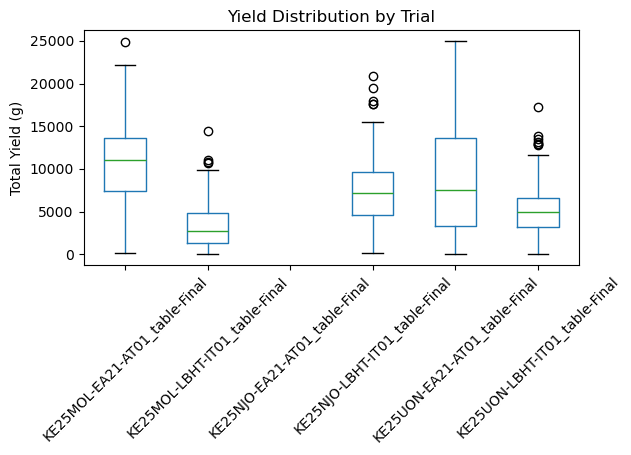

In [102]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

master_clean.boxplot(
    column="weight_g_total",
    by="trial",
    rot=45,
    grid=False
)

plt.title("Yield Distribution by Trial")
plt.suptitle("")
plt.xlabel("")
plt.ylabel("Total Yield (g)")

plt.tight_layout()

plt.show()

In [103]:
trial_summary = (
    master_clean
    .groupby("trial", observed=False)
    .agg(
        Plots=("weight_g_total", "count"),
        Mean_Yield=("weight_g_total", "mean"),
        Median_Yield=("weight_g_total", "median"),
        SD=("weight_g_total", "std"),
        Minimum=("weight_g_total", "min"),
        Maximum=("weight_g_total", "max")
    )
    .round(1)
)

trial_summary

,Plots,Mean_Yield,Median_Yield,SD,Minimum,Maximum
trial,,,,,,
KE25MOL-EA21-AT01_table-Final,173,10856.1,11054.5,5234.4,201.9,24840.6
KE25MOL-LBHT-IT01_table-Final,261,3335.5,2787.4,2570.7,36.2,14475.6
KE25NJO-EA21-AT01_table-Final,0,NaN,NaN,NaN,NaN,NaN
KE25NJO-LBHT-IT01_table-Final,262,7402.5,7235.6,3900.8,94.2,20932.8
KE25UON-EA21-AT01_table-Final,169,8620.7,7506.4,6316.3,3.2,24995.7
KE25UON-LBHT-IT01_table-Final,262,5121.2,4900.3,2872.3,1.6,17319.2


In [104]:
master_clean.loc[
    master_clean["trial"] == "KE25NJO-EA21-AT01_table-Final",
    [
        "weight_g_total",
        "total_weight_in_kgs",
        "weight_in_air_kgs",
        "weight_in_water_kgs"
    ]
].describe(include="all")

,weight_g_total,total_weight_in_kgs,weight_in_air_kgs,weight_in_water_kgs
count,0.0,174.000000,174.000000,174.000000
mean,NaN,9.048103,4.654540,0.227816
std,NaN,5.556411,1.537919,0.099704
min,NaN,0.000000,0.000000,0.000000
25%,NaN,5.030000,4.220000,0.180000
50%,NaN,8.600000,5.080000,0.240000
75%,NaN,12.445000,5.560000,0.295000
max,NaN,30.000000,7.400000,0.520000


In [105]:
# ----------------------------------------------------------
# Harmonize total yield for KE25NJO-EA21
# ----------------------------------------------------------

mask = (
    (master_clean["trial"] == "KE25NJO-EA21-AT01_table-Final") &
    (master_clean["weight_g_total"].isna())
)

print(f"Rows to harmonize: {mask.sum()}")

master_clean.loc[
    mask,
    "weight_g_total"
] = (
    master_clean.loc[
        mask,
        "total_weight_in_kgs"
    ] * 1000
)

print("Yield harmonization completed.")

Rows to harmonize: 174
Yield harmonization completed.


In [106]:
master_clean.loc[
    master_clean["trial"] == "KE25NJO-EA21-AT01_table-Final",
    ["weight_g_total", "total_weight_in_kgs"]
].head(10)

,weight_g_total,total_weight_in_kgs
438,15460.0,15.46
439,7240.0,7.24
440,460.0,0.46
441,6940.0,6.94
442,2280.0,2.28
443,7240.0,7.24
444,7100.0,7.10
445,2040.0,2.04
446,13140.0,13.14
447,6680.0,6.68


In [107]:
yield_missing = (
    master_clean
    .groupby("trial", observed=False)
    .agg(
        Total_Plots=("weight_g_total", "size"),
        Missing_Yield=("weight_g_total", lambda x: x.isna().sum()),
        Recorded_Yield=("weight_g_total", lambda x: x.notna().sum())
    )
)

yield_missing["Missing_%"] = (
    yield_missing["Missing_Yield"] /
    yield_missing["Total_Plots"] * 100
).round(1)

yield_missing

,Total_Plots,Missing_Yield,Recorded_Yield,Missing_%
trial,,,,
KE25MOL-EA21-AT01_table-Final,174,1,173,0.6
KE25MOL-LBHT-IT01_table-Final,264,3,261,1.1
KE25NJO-EA21-AT01_table-Final,174,0,174,0.0
KE25NJO-LBHT-IT01_table-Final,264,2,262,0.8
KE25UON-EA21-AT01_table-Final,180,11,169,6.1
KE25UON-LBHT-IT01_table-Final,264,2,262,0.8


In [108]:
# Record how weight_g_total was populated
master_clean["yield_source"] = "Original weight_g_total"

master_clean.loc[
    master_clean["trial"] == "KE25NJO-EA21-AT01_table-Final",
    "yield_source"
] = "Converted from total_weight_in_kgs"

In [109]:
master_clean["yield_source"].value_counts()

yield_source
Original weight_g_total               1146
Converted from total_weight_in_kgs     174
Name: count, dtype: int64

### Yield Harmonization Summary

A data audit identified that the KE25NJO-EA21-AT01 trial contained no observations in the `weight_g_total` variable. Inspection of the original trial data confirmed that harvested plot yield had instead been recorded as `total_weight_in_kgs`. These values were converted to grams (`×1000`) and used to populate `weight_g_total`, thereby harmonizing the yield variable across all six trial environments. Following harmonization, yield data were available for all environments, with overall missingness remaining below 7% in every trial.

In [110]:
# ---------------------------------------------------------
# Environment summary statistics
# ---------------------------------------------------------

env_summary = (
    master_clean
    .groupby("trial", observed=False)
    .agg(
        Plots=("weight_g_total", "count"),
        Mean_Yield=("weight_g_total", "mean"),
        Median_Yield=("weight_g_total", "median"),
        SD=("weight_g_total", "std"),
        Minimum=("weight_g_total", "min"),
        Maximum=("weight_g_total", "max")
    )
)

env_summary["CV_%"] = (
    env_summary["SD"] /
    env_summary["Mean_Yield"] * 100
)

env_summary = env_summary.round(2)

env_summary

,Plots,Mean_Yield,Median_Yield,SD,Minimum,Maximum,CV_%
trial,,,,,,,
KE25MOL-EA21-AT01_table-Final,173,10856.08,11054.50,5234.37,201.9,24840.6,48.22
KE25MOL-LBHT-IT01_table-Final,261,3335.50,2787.40,2570.69,36.2,14475.6,77.07
KE25NJO-EA21-AT01_table-Final,174,9048.10,8600.00,5556.41,0.0,30000.0,61.41
KE25NJO-LBHT-IT01_table-Final,262,7402.47,7235.65,3900.75,94.2,20932.8,52.70
KE25UON-EA21-AT01_table-Final,169,8620.66,7506.40,6316.28,3.2,24995.7,73.27
KE25UON-LBHT-IT01_table-Final,262,5121.24,4900.30,2872.32,1.6,17319.2,56.09


## Yield Performance Across Trial Environments

## 2.7 Environment Characterization

### Interpretation of Yield Performance Across Trial Environments

The six trial environments exhibited substantial differences in yield performance, indicating strong environmental effects on potato productivity. Mean plot yield ranged from **3.34 kg** in the Molo Late Blight Hotspot Trial (KE25MOL-LBHT-IT01) to **10.86 kg** in the Molo Advanced Trial (KE25MOL-EA21-AT01), demonstrating more than a threefold difference in productivity across environments.

The **KE25MOL-EA21** trial recorded the highest mean yield (10,856 g plot⁻¹) and the highest median yield (11,055 g plot⁻¹), suggesting favourable growing conditions that supported consistently high productivity across genotypes. In contrast, the **KE25MOL-LBHT** trial had the lowest average yield (3,336 g plot⁻¹), representing approximately 31% of the yield achieved in the corresponding advanced trial. This reduction is consistent with the expected effects of increased disease pressure in late blight hotspot trials.

Across all three locations (Molo, Njoro and UoN), the advanced trials (EA21) generally produced higher average yields than the corresponding Late Blight Hotspot Trials (LBHT), highlighting the influence of environmental conditions and disease pressure on yield performance.

The coefficient of variation (CV%) further demonstrated differences in within-environment variability. The **KE25MOL-EA21** trial exhibited the lowest relative variability (CV = 48.2%), indicating comparatively uniform plot performance. Conversely, the **KE25MOL-LBHT** (CV = 77.1%) and **KE25UON-EA21** (CV = 73.3%) trials showed substantially greater variability, suggesting stronger discrimination among genotypes but also increased environmental heterogeneity. Such environments are valuable for identifying superior genotypes, although they require appropriate statistical adjustment to separate genetic effects from environmental variation.

The observed yield ranges also reflected considerable diversity among the evaluated breeding clones. Maximum plot yields exceeded **24 kg** in several environments, while minimum yields approached zero in a few cases, indicating the presence of both exceptionally high-performing and poorly performing genotypes. These observations justify the application of spatial mixed models in subsequent analyses to partition environmental variation from genetic performance and to obtain reliable estimates of genotype merit.

# Visualizing mean yield across environments

mean yield across trial environments

In [111]:
# ==========================================================
# Figure 1: Environment Yield Summary
# ==========================================================

plot_df = (
    env_summary
    .reset_index()
    .copy()
)

# Convert grams to kilograms
plot_df["Mean_Yield_kg"] = plot_df["Mean_Yield"] / 1000
plot_df["SD_kg"] = plot_df["SD"] / 1000

# Short trial names
trial_labels = {
    "KE25MOL-EA21-AT01_table-Final": "Molo EA21",
    "KE25MOL-LBHT-IT01_table-Final": "Molo LBHT",
    "KE25NJO-EA21-AT01_table-Final": "Njoro EA21",
    "KE25NJO-LBHT-IT01_table-Final": "Njoro LBHT",
    "KE25UON-EA21-AT01_table-Final": "UoN EA21",
    "KE25UON-LBHT-IT01_table-Final": "UoN LBHT",
}

plot_df["Environment"] = plot_df["trial"].map(trial_labels)

# Sort by mean yield
plot_df = plot_df.sort_values(
    "Mean_Yield_kg",
    ascending=False
)

plot_df

,trial,Plots,Mean_Yield,Median_Yield,SD,Minimum,Maximum,CV_%,Mean_Yield_kg,SD_kg,Environment
0,KE25MOL-EA21-AT01_table-Final,173,10856.08,11054.50,5234.37,201.9,24840.6,48.22,10.85608,5.23437,Molo EA21
2,KE25NJO-EA21-AT01_table-Final,174,9048.10,8600.00,5556.41,0.0,30000.0,61.41,9.04810,5.55641,Njoro EA21
4,KE25UON-EA21-AT01_table-Final,169,8620.66,7506.40,6316.28,3.2,24995.7,73.27,8.62066,6.31628,UoN EA21
3,KE25NJO-LBHT-IT01_table-Final,262,7402.47,7235.65,3900.75,94.2,20932.8,52.70,7.40247,3.90075,Njoro LBHT
5,KE25UON-LBHT-IT01_table-Final,262,5121.24,4900.30,2872.32,1.6,17319.2,56.09,5.12124,2.87232,UoN LBHT
1,KE25MOL-LBHT-IT01_table-Final,261,3335.50,2787.40,2570.69,36.2,14475.6,77.07,3.33550,2.57069,Molo LBHT


The plot


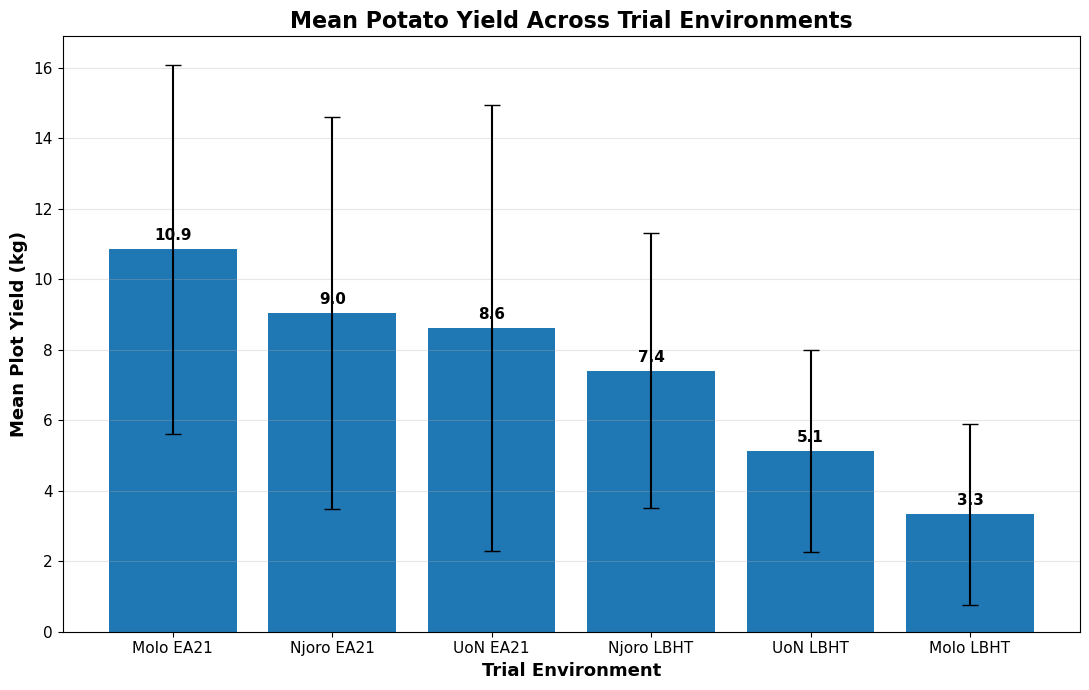

In [112]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11,7))

bars = plt.bar(
    plot_df["Environment"],
    plot_df["Mean_Yield_kg"],
    yerr=plot_df["SD_kg"],
    capsize=6
)

# Value labels
for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.25,
        f"{height:.1f}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.ylabel(
    "Mean Plot Yield (kg)",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel(
    "Trial Environment",
    fontsize=13,
    fontweight="bold"
)

plt.title(
    "Mean Potato Yield Across Trial Environments",
    fontsize=16,
    fontweight="bold"
)

plt.xticks(fontsize=11)

plt.yticks(fontsize=11)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [113]:
# ==========================================================
# Figure 1 Data Preparation
# ==========================================================

import pandas as pd

# Create plotting dataframe
fig1 = env_summary.reset_index().copy()

# Convert yield from grams to kilograms
fig1["Mean_Yield_kg"] = fig1["Mean_Yield"] / 1000

# Short trial names
trial_map = {
    "KE25MOL-EA21-AT01_table-Final": "Molo EA21",
    "KE25MOL-LBHT-IT01_table-Final": "Molo LBHT",
    "KE25NJO-EA21-AT01_table-Final": "Njoro EA21",
    "KE25NJO-LBHT-IT01_table-Final": "Njoro LBHT",
    "KE25UON-EA21-AT01_table-Final": "UoN EA21",
    "KE25UON-LBHT-IT01_table-Final": "UoN LBHT"
}

fig1["Environment"] = fig1["trial"].map(trial_map)

# Sort environments by productivity
fig1 = fig1.sort_values(
    "Mean_Yield_kg",
    ascending=False
)

display(fig1)

,trial,Plots,Mean_Yield,Median_Yield,SD,Minimum,Maximum,CV_%,Mean_Yield_kg,Environment
0,KE25MOL-EA21-AT01_table-Final,173,10856.08,11054.50,5234.37,201.9,24840.6,48.22,10.85608,Molo EA21
2,KE25NJO-EA21-AT01_table-Final,174,9048.10,8600.00,5556.41,0.0,30000.0,61.41,9.04810,Njoro EA21
4,KE25UON-EA21-AT01_table-Final,169,8620.66,7506.40,6316.28,3.2,24995.7,73.27,8.62066,UoN EA21
3,KE25NJO-LBHT-IT01_table-Final,262,7402.47,7235.65,3900.75,94.2,20932.8,52.70,7.40247,Njoro LBHT
5,KE25UON-LBHT-IT01_table-Final,262,5121.24,4900.30,2872.32,1.6,17319.2,56.09,5.12124,UoN LBHT
1,KE25MOL-LBHT-IT01_table-Final,261,3335.50,2787.40,2570.69,36.2,14475.6,77.07,3.33550,Molo LBHT


/tmp/ipykernel_19107/1576749184.py:48: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = plt.boxplot(


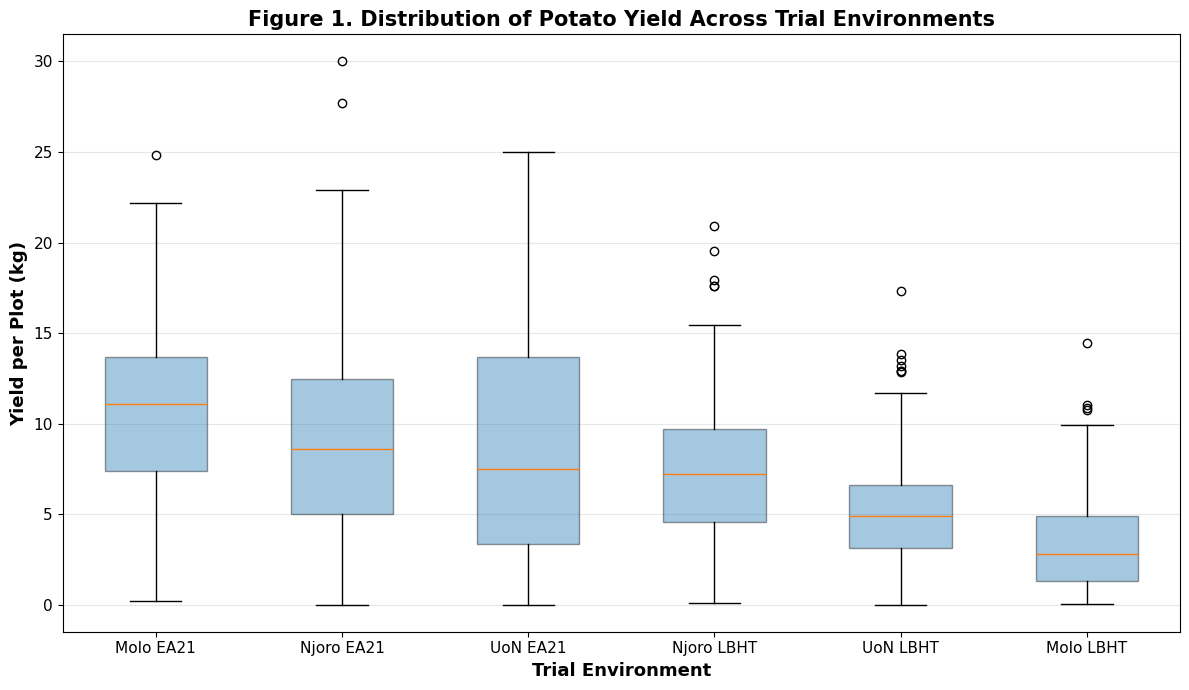

In [114]:
import matplotlib.pyplot as plt

# ==========================================================
# Publication Figure 1
# Yield Distribution Across Environments
# ==========================================================

# Short environment names
trial_map = {
    "KE25MOL-EA21-AT01_table-Final": "Molo EA21",
    "KE25MOL-LBHT-IT01_table-Final": "Molo LBHT",
    "KE25NJO-EA21-AT01_table-Final": "Njoro EA21",
    "KE25NJO-LBHT-IT01_table-Final": "Njoro LBHT",
    "KE25UON-EA21-AT01_table-Final": "UoN EA21",
    "KE25UON-LBHT-IT01_table-Final": "UoN LBHT"
}

plot_data = master_clean.copy()

plot_data["Environment"] = (
    plot_data["trial"]
    .map(trial_map)
)

plot_data["Yield_kg"] = (
    plot_data["weight_g_total"] / 1000
)

order = [
    "Molo EA21",
    "Njoro EA21",
    "UoN EA21",
    "Njoro LBHT",
    "UoN LBHT",
    "Molo LBHT"
]

data = [
    plot_data.loc[
        plot_data["Environment"] == env,
        "Yield_kg"
    ].dropna()
    for env in order
]

plt.figure(figsize=(12,7))

bp = plt.boxplot(
    data,
    labels=order,
    patch_artist=True,
    widths=0.55,
    showfliers=True
)

# Light fill for boxes (keeps default color palette)
for box in bp["boxes"]:
    box.set_alpha(0.4)

plt.ylabel(
    "Yield per Plot (kg)",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel(
    "Trial Environment",
    fontsize=13,
    fontweight="bold"
)

plt.title(
    "Figure 1. Distribution of Potato Yield Across Trial Environments",
    fontsize=15,
    fontweight="bold"
)

plt.grid(
    axis="y",
    alpha=0.30
)

plt.xticks(fontsize=11)

plt.yticks(fontsize=11)

plt.tight_layout()

plt.savefig(
    "Figure1_Yield_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

The distribution of plot yield varied considerably across the six trial environments (Figure 1). The advanced evaluation trials (EA21) generally exhibited higher median yields than the corresponding late blight hotspot trials (LBHT), indicating that environmental conditions and disease pressure strongly influenced potato productivity.

Among the advanced trials, **Molo EA21** recorded the highest median yield and relatively consistent performance across genotypes, whereas **UoN EA21** displayed the widest interquartile range, reflecting substantial variability among breeding clones. This wide distribution suggests that the environment effectively discriminated between superior and inferior genotypes, making it valuable for selection.

The late blight hotspot trials consistently produced lower yield distributions than their corresponding advanced trials. In particular, **Molo LBHT** showed the lowest median yield and a relatively narrow interquartile range, indicating reduced productivity under high disease pressure. Nevertheless, the presence of several high-yielding outliers across the hotspot trials demonstrates that a subset of genotypes maintained favourable performance despite the challenging conditions.

Overall, the marked differences in yield distributions among environments provide clear evidence of environmental heterogeneity and support the need for multi-environment and spatial mixed-model analyses to accurately partition genetic and environmental sources of variation.

**Key Takeaways**

- Yield distributions differed substantially among the six trial environments.
- Advanced trials generally produced higher yields than Late Blight Hotspot Trials.
- UoN EA21 exhibited the greatest variability, suggesting strong discriminatory power for genotype evaluation.
- High-yielding outliers were observed in all environments, indicating the presence of promising breeding clones.
- The observed environmental heterogeneity justifies the application of mixed-model and spatial analyses in subsequent stages.

# Exploratory Breeding Analytics
### Section 2 – Genotype Performance Across Environments
### Scientific Question

Which potato breeding clones exhibited the highest yield within each trial environment, and how consistent was genotype performance across environments?

# Step 2.1 — Creating a Genotype Performance Summary

In [115]:
# ==========================================================
# Genotype performance within each environment
# ==========================================================

geno_env = (
    master_clean
    .groupby(
        ["trial", "geno"],
        observed=True      # <-- IMPORTANT CHANGE
    )
    .agg(
        Mean_Yield=("weight_g_total", "mean"),
        Median_Yield=("weight_g_total", "median"),
        SD=("weight_g_total", "std"),
        Plots=("weight_g_total", "count")
    )
    .reset_index()
)

geno_env["Mean_Yield_kg"] = geno_env["Mean_Yield"] / 1000

geno_env.head()

,trial,geno,Mean_Yield,Median_Yield,SD,Plots,Mean_Yield_kg
0,KE25MOL-EA21-AT01_table-Final,CIP312010.759,10479.000000,10423.5,1489.825523,3,10.479000
1,KE25MOL-EA21-AT01_table-Final,CIP312084.731,7510.800000,6296.5,3708.477778,3,7.510800
2,KE25MOL-EA21-AT01_table-Final,CIP3177023.046,3035.533333,2418.0,2645.029815,3,3.035533
3,KE25MOL-EA21-AT01_table-Final,CIP3177033.071,5618.166667,5323.1,1377.509061,3,5.618167
4,KE25MOL-EA21-AT01_table-Final,CIP3187015.677,16777.800000,15580.1,3503.415803,3,16.777800


## 2.1 Trial Balance Assessment

### Scientific Question

Before comparing genotype performance, it is important to evaluate whether genotypes were represented by a sufficient number of observations within each trial environment. Reliable genotype ranking requires adequate replication to reduce the influence of random environmental variation.

In [116]:
geno_env["Plots"].value_counts().sort_index()

Plots
0      5
1     44
2    280
3    145
4     22
5     10
6     14
7      2
8      1
9      2
Name: count, dtype: int64

In [117]:
geno_rank = geno_env.query("Plots >= 2").copy()

print(f"Original genotype-environment combinations: {len(geno_env)}")
print(f"Retained for ranking: {len(geno_rank)}")
print(f"Removed: {len(geno_env) - len(geno_rank)}")

Original genotype-environment combinations: 525
Retained for ranking: 476
Removed: 49


### Interpretation

A total of **525 genotype × environment combinations** were identified across the six trial environments. To improve the reliability of exploratory genotype comparisons, combinations represented by fewer than two observations were excluded from subsequent ranking analyses. This quality-control step retained **476 combinations (90.7%)**, while only **49 combinations (9.3%)** were removed.

The advanced evaluation (EA21) trials exhibited a highly balanced structure, with approximately three observations per genotype across environments. In contrast, the late blight hotspot (LBHT) trials were more heterogeneous, averaging just over two observations per genotype. Such imbalance is expected in breeding programs, where missing plots, poor emergence, disease damage, and selection decisions often result in unequal representation of breeding clones.

Overall, the high proportion of retained genotype–environment combinations indicates that the dataset provides a robust foundation for exploratory genotype evaluation while highlighting the need for mixed-model analyses to account for the remaining imbalance in the experimental design.

**Key Takeaways**

- A total of 525 genotype × environment combinations were identified.
- Applying a minimum threshold of two observations retained over 90% of the data.
- EA21 trials were highly balanced, whereas LBHT trials showed moderate imbalance.
- The remaining imbalance reinforces the need for mixed-model analyses in later stages.

In [118]:
master_clean.groupby("trial").agg(
    Rows=("geno", "size"),
    Unique_Genotypes=("geno", "nunique")
)

,Rows,Unique_Genotypes
trial,,
KE25MOL-EA21-AT01_table-Final,174,58
KE25MOL-LBHT-IT01_table-Final,264,118
KE25NJO-EA21-AT01_table-Final,174,58
KE25NJO-LBHT-IT01_table-Final,264,112
KE25UON-EA21-AT01_table-Final,180,59
KE25UON-LBHT-IT01_table-Final,264,120


# Scientific Question

How does the distribution of genotype mean yield differ among the six trial environments after accounting for within-genotype replication?

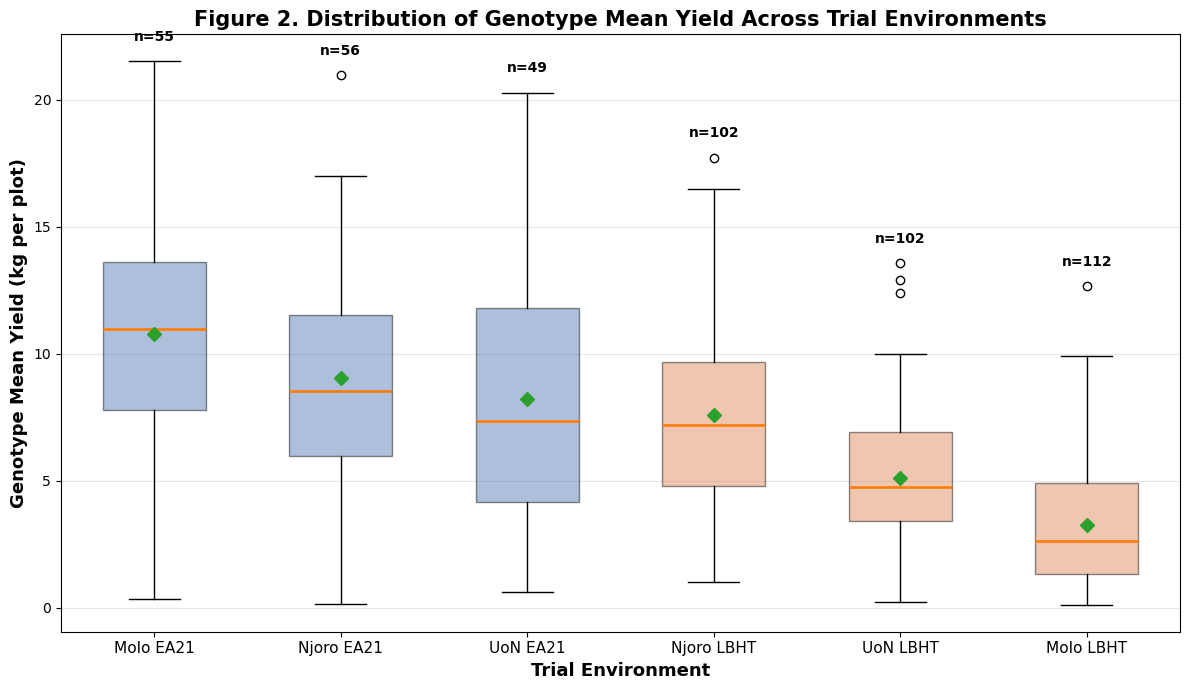

In [119]:
# ==========================================================
# Figure 2
# Distribution of Genotype Mean Yield by Environment
# ==========================================================

import matplotlib.pyplot as plt
import numpy as np

# ----------------------------------------------------------
# Use only reliable genotype-environment combinations
# ----------------------------------------------------------
geno_rank = geno_env.query("Plots >= 2").copy()

# Convert yield to kg
geno_rank["Mean_Yield_kg"] = geno_rank["Mean_Yield"] / 1000

# Short environment names
trial_map = {
    "KE25MOL-EA21-AT01_table-Final": "Molo EA21",
    "KE25MOL-LBHT-IT01_table-Final": "Molo LBHT",
    "KE25NJO-EA21-AT01_table-Final": "Njoro EA21",
    "KE25NJO-LBHT-IT01_table-Final": "Njoro LBHT",
    "KE25UON-EA21-AT01_table-Final": "UoN EA21",
    "KE25UON-LBHT-IT01_table-Final": "UoN LBHT"
}

geno_rank["Environment"] = geno_rank["trial"].map(trial_map)

# Order environments by productivity
order = [
    "Molo EA21",
    "Njoro EA21",
    "UoN EA21",
    "Njoro LBHT",
    "UoN LBHT",
    "Molo LBHT"
]

# ----------------------------------------------------------
# Prepare data
# ----------------------------------------------------------
plot_data = [
    geno_rank.loc[
        geno_rank["Environment"] == env,
        "Mean_Yield_kg"
    ].dropna()
    for env in order
]

# ----------------------------------------------------------
# Create publication-quality figure
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(12,7))

bp = ax.boxplot(
    plot_data,
    patch_artist=True,
    widths=0.55,
    showmeans=True,
    meanline=False,
    medianprops=dict(linewidth=2),
    meanprops=dict(
        marker='D',
        markersize=7,
    )
)

# Alternate colours:
# EA21 = blue shades
# LBHT = orange shades
colors = [
    "#4C72B0",
    "#4C72B0",
    "#4C72B0",
    "#DD8452",
    "#DD8452",
    "#DD8452"
]

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.45)

# Add number of genotypes above each box
for i, env in enumerate(order):
    n = geno_rank.loc[
        geno_rank["Environment"] == env,
        "geno"
    ].nunique()

    ymax = plot_data[i].max()

    ax.text(
        i+1,
        ymax + 0.8,
        f"n={n}",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xticklabels(order, fontsize=11)

ax.set_ylabel(
    "Genotype Mean Yield (kg per plot)",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel(
    "Trial Environment",
    fontsize=13,
    fontweight="bold"
)

ax.set_title(
    "Figure 2. Distribution of Genotype Mean Yield Across Trial Environments",
    fontsize=15,
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "Figure2_Genotype_Mean_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Figure 2 illustrates the distribution of genotype mean yield within each trial environment after excluding genotype–environment combinations represented by fewer than two observations. Averaging yield across repeated observations reduced within-genotype variability and provided a clearer representation of genetic performance compared with the individual plot distributions shown in Figure 1.

The EA21 environments generally exhibited higher genotype mean yields than the late blight hotspot (LBHT) environments. Molo EA21 recorded the highest median genotype yield and also contained the highest-yielding individual genotypes, indicating favourable growing conditions and strong discrimination among breeding clones. Njoro EA21 and UoN EA21 similarly supported high-yielding genotypes, although UoN EA21 displayed greater variability, suggesting stronger genotype-by-environment responses.

Among the hotspot environments, Njoro LBHT produced the highest genotype yields, whereas Molo LBHT showed the lowest overall genotype performance. The compressed distribution observed in Molo LBHT indicates that disease pressure substantially reduced yield across most breeding clones, although a small number of genotypes maintained comparatively high performance.

The presence of high-yielding outliers in several environments demonstrates that superior genetic material exists despite considerable environmental variation. These elite-performing genotypes warrant further investigation using spatial mixed models to determine whether their superior performance remains after adjusting for field heterogeneity and experimental imbalance.

**Key Takeaways**

- Genotype mean yields varied substantially across environments.
- EA21 trials consistently produced higher genotype yields than LBHT trials.
- Molo EA21 exhibited the highest median genotype yield and the widest range of superior-performing clones.
- Molo LBHT imposed the greatest yield reduction, consistent with strong disease pressure.
- Several exceptionally high-yielding genotypes were identified and will be evaluated further using adjusted mixed-model analyses.

# SECTION 3. Genotype Performance
## 3.1 Identifying Elite Genotypes Within Each Environment
### Scientific Question

Which genotypes exhibited the highest mean tuber yield within each trial environment?

creating the Top 10 genotype table

In [120]:
# ==========================================================
# Top 10 genotypes within each environment
# ==========================================================

top10 = (
    geno_rank
    .sort_values(
        ["trial", "Mean_Yield"],
        ascending=[True, False]
    )
    .groupby("trial", observed=True)
    .head(10)
    .copy()
)

# Short environment names
top10["Environment"] = top10["trial"].map(trial_map)

# Display table
top10 = top10[[
    "Environment",
    "geno",
    "Mean_Yield_kg",
    "Plots",
    "SD"
]]

top10 = top10.sort_values(
    ["Environment", "Mean_Yield_kg"],
    ascending=[True, False]
)

top10

,Environment,geno,Mean_Yield_kg,Plots,SD
27,Molo EA21,CIP3217008.098,21.509100,3,3484.213743
9,Molo EA21,CIP3217004.022,19.709100,3,1018.880871
20,Molo EA21,CIP3217006.021,19.502267,3,2303.341287
49,Molo EA21,CIP3217019.001,18.508067,3,2230.678680
4,Molo EA21,CIP3187015.677,16.777800,3,3503.415803
...,...,...,...,...,...
476,UoN LBHT,CIP316361.094,9.644633,3,2044.082585
453,UoN LBHT,CIP316358.029,9.284033,3,2382.870333
433,UoN LBHT,CIP316353.019,8.979400,5,3921.273042
467,UoN LBHT,CIP316361.022,8.846100,2,1782.757617


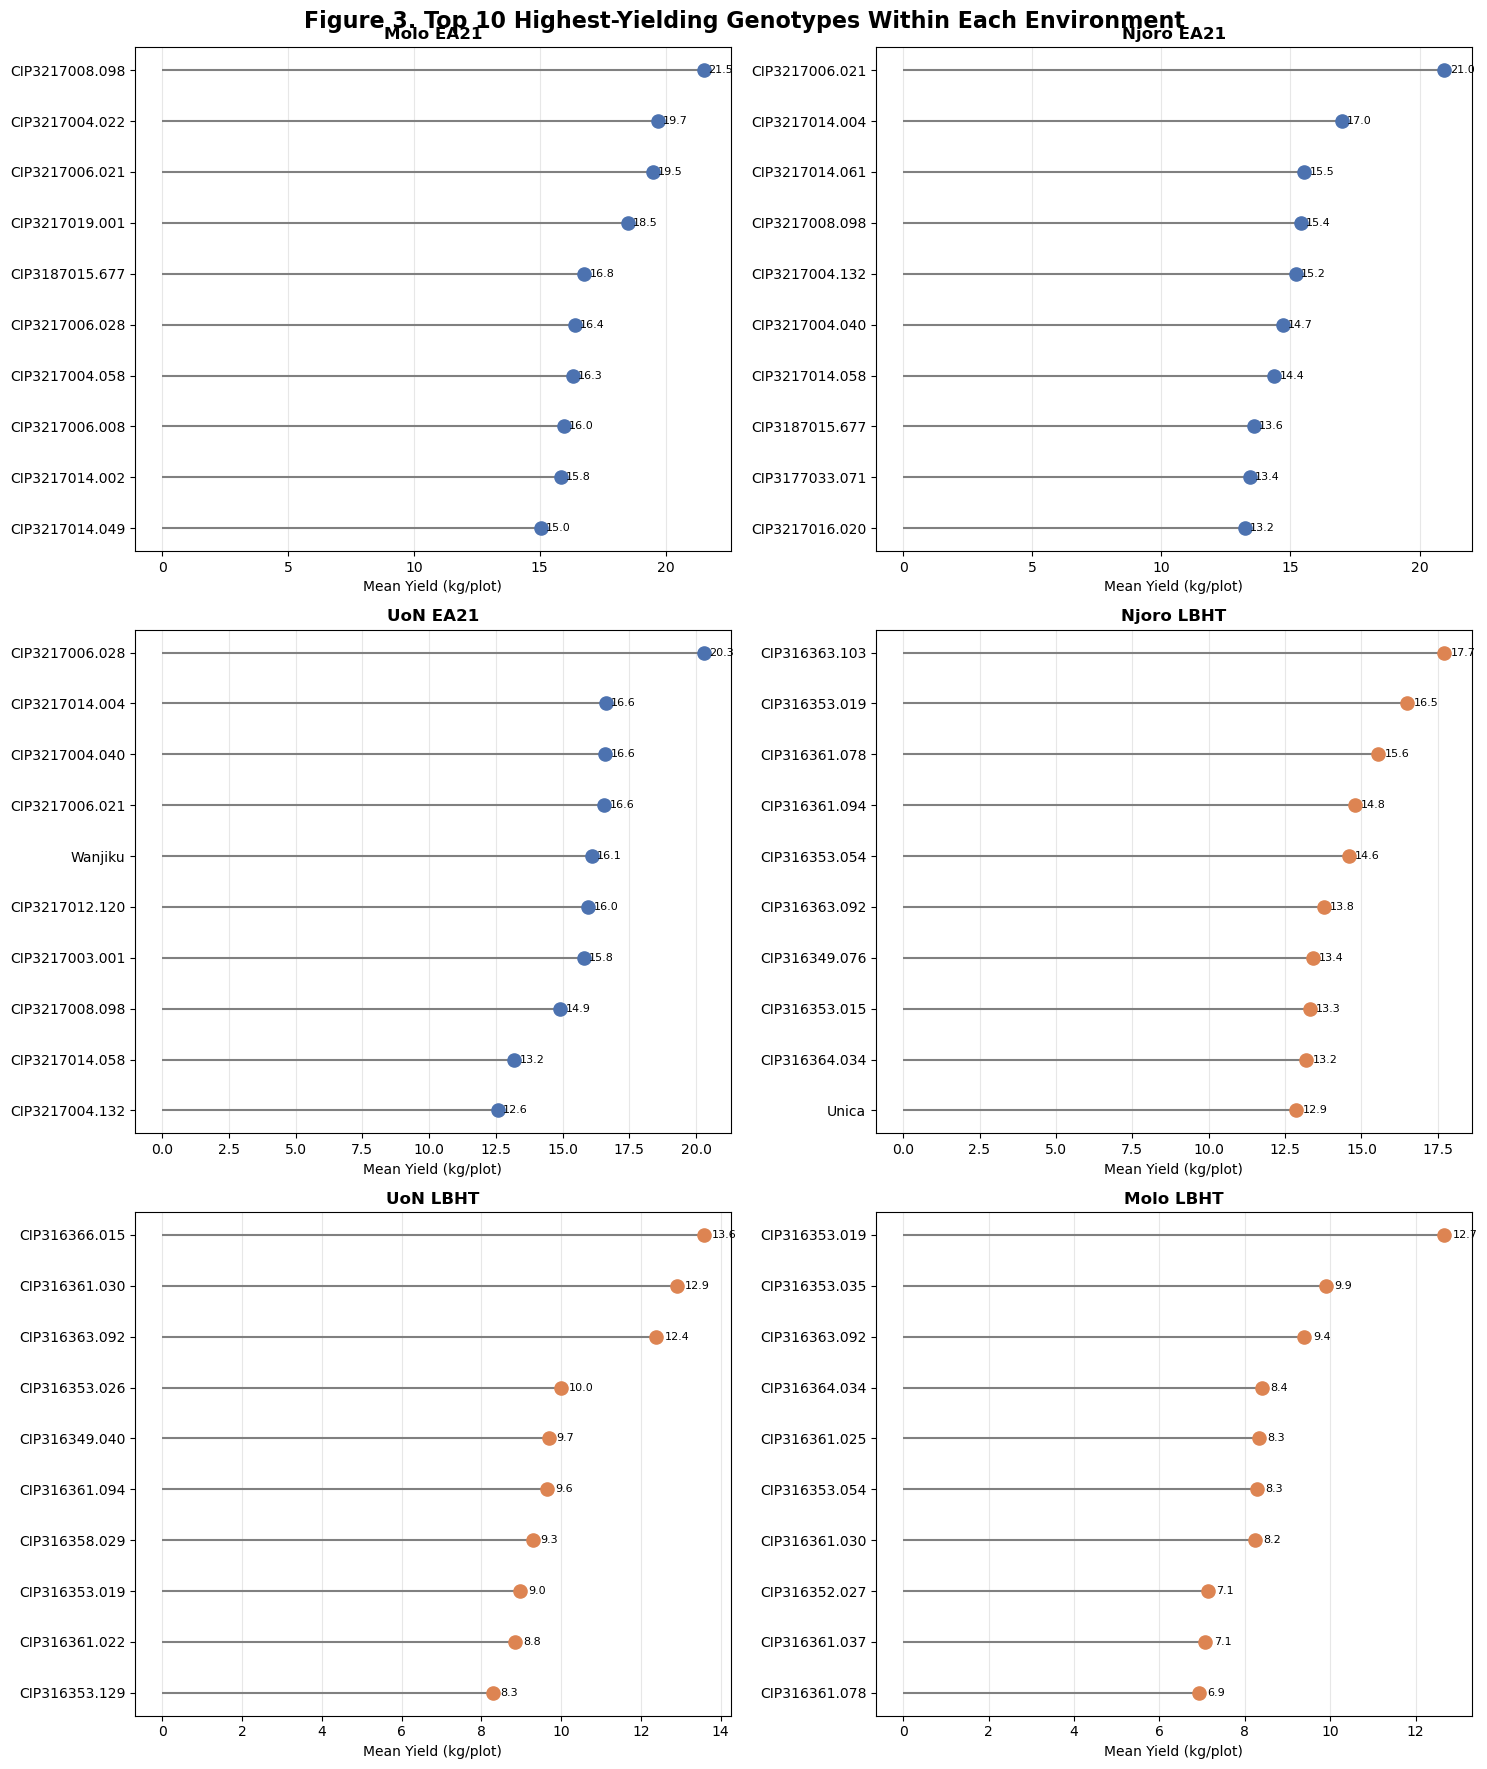

In [121]:
# ==========================================================
# Figure 3
# Top 10 Genotypes by Environment
# ==========================================================

import matplotlib.pyplot as plt

environments = [
    "Molo EA21",
    "Njoro EA21",
    "UoN EA21",
    "Njoro LBHT",
    "UoN LBHT",
    "Molo LBHT"
]

fig, axes = plt.subplots(
    3,
    2,
    figsize=(15, 18)
)

axes = axes.flatten()

for ax, env in zip(axes, environments):

    df = (
        top10
        .loc[top10["Environment"] == env]
        .sort_values("Mean_Yield_kg")
    )

    color = "#4C72B0" if "EA21" in env else "#DD8452"

    # Lollipop stems
    ax.hlines(
        y=df["geno"],
        xmin=0,
        xmax=df["Mean_Yield_kg"],
        color="grey",
        linewidth=1.5
    )

    # Lollipop heads
    ax.scatter(
        df["Mean_Yield_kg"],
        df["geno"],
        s=90,
        color=color,
        zorder=3
    )

    # Yield labels
    for _, row in df.iterrows():
        ax.text(
            row["Mean_Yield_kg"] + 0.2,
            row["geno"],
            f"{row['Mean_Yield_kg']:.1f}",
            va="center",
            fontsize=8
        )

    ax.set_title(
        env,
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Mean Yield (kg/plot)")
    ax.grid(axis="x", alpha=0.3)

plt.suptitle(
    "Figure 3. Top 10 Highest-Yielding Genotypes Within Each Environment",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "Figure3_Top10_Genotypes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Figure 3 presents the ten highest-yielding genotypes identified within each trial environment after excluding genotype–environment combinations represented by fewer than two observations. Considerable differences in elite genotype performance were observed across environments.

The three EA21 environments consistently produced the highest-performing genotypes, with the leading clones exceeding 20 kg per plot in both Molo EA21 and UoN EA21. Molo EA21 recorded the highest observed genotype mean yield (21.5 kg per plot), demonstrating that favourable production environments allowed superior genetic potential to be fully expressed.

In contrast, the late blight hotspot (LBHT) environments exhibited lower maximum yields, with the highest-performing genotypes reaching approximately 17.7 kg, 13.8 kg and 12.7 kg per plot in Njoro, UoN and Molo, respectively. These reductions are consistent with the expected effects of disease pressure on tuber production.

The ranking patterns also indicate substantial genetic variability within each environment. While several elite genotypes clearly outperformed the remainder of the breeding population, the identity of the highest-yielding clones differed among environments, suggesting the presence of genotype × environment interaction. This observation highlights the importance of evaluating breeding material across multiple testing sites before advancement decisions are made.

The elite-performing genotypes identified in this exploratory analysis represent promising candidates for subsequent mixed-model evaluation, where spatial adjustment and Best Linear Unbiased Predictions (BLUPs) will be used to determine whether their superiority remains after accounting for environmental heterogeneity.

**Key Takeaways**

- Elite genotype performance differed among environments.
- The highest raw yield (21.5 kg per plot) was observed in Molo EA21.
- EA21 environments consistently supported greater yield expression than LBHT environments.
- Disease hotspot environments reduced overall yield but still identified superior breeding material.
- Differences in genotype rankings across environments suggest the presence of genotype × environment interaction, warranting formal mixed-model analysis.

# SECTION 3.2 Cross-Environment Elite Genotype Identification
### Scientific Question

Which genotypes consistently ranked among the highest-yielding across multiple trial environments?

This is much more important than simply listing the top 10 in each environment.

Remember:

- A genotype that is 1st in one environment but absent elsewhere may be specifically adapted.
- A genotype that appears in the Top 10 across several environments is much more valuable because it suggests broad adaptation and yield stability.

### Step 1. Count how many environments each genotype appears in the Top 10

In [122]:
# ==========================================================
# Cross-environment Top 10 frequency
# ==========================================================

elite_frequency = (
    top10
    .groupby("geno", observed=True)
    .agg(
        Environments=("Environment", "nunique"),
        Mean_of_Means=("Mean_Yield_kg", "mean"),
        Best_Yield=("Mean_Yield_kg", "max")
    )
    .reset_index()
)

elite_frequency = elite_frequency.sort_values(
    ["Environments", "Mean_of_Means"],
    ascending=[False, False]
)

elite_frequency

,geno,Environments,Mean_of_Means,Best_Yield
28,CIP3217006.021,3,19.008467,20.966667
30,CIP3217008.098,3,17.272178,21.509100
4,CIP316353.019,3,12.717617,16.500800
16,CIP316363.092,3,11.851650,13.776800
29,CIP3217006.028,2,18.339033,20.280267
...,...,...,...,...
10,CIP316361.022,1,8.846100,8.846100
11,CIP316361.025,1,8.326900,8.326900
8,CIP316353.129,1,8.279900,8.279900
2,CIP316352.027,1,7.125700,7.125700


### Want to see which environments (recording where each genotype performed well)

In [123]:
# ==========================================================
# Elite genotype environments
# ==========================================================

elite_env = (
    top10
    .groupby("geno", observed=True)
    .agg(
        Environments=("Environment",
                      lambda x: ", ".join(sorted(x.unique()))),
        Frequency=("Environment", "nunique"),
        Mean_Yield=("Mean_Yield_kg", "mean")
    )
    .reset_index()
)

elite_env = elite_env.sort_values(
    ["Frequency", "Mean_Yield"],
    ascending=[False, False]
)

elite_env.head(25)

,geno,Environments,Frequency,Mean_Yield
28,CIP3217006.021,"Molo EA21, Njoro EA21, UoN EA21",3,19.008467
30,CIP3217008.098,"Molo EA21, Njoro EA21, UoN EA21",3,17.272178
4,CIP316353.019,"Molo LBHT, Njoro LBHT, UoN LBHT",3,12.717617
16,CIP316363.092,"Molo LBHT, Njoro LBHT, UoN LBHT",3,11.851650
29,CIP3217006.028,"Molo EA21, UoN EA21",2,18.339033
...,...,...,...,...
27,CIP3217006.008,Molo EA21,1,15.964467
31,CIP3217012.120,UoN EA21,1,15.951867
32,CIP3217014.002,Molo EA21,1,15.827733
22,CIP3217003.001,UoN EA21,1,15.784667


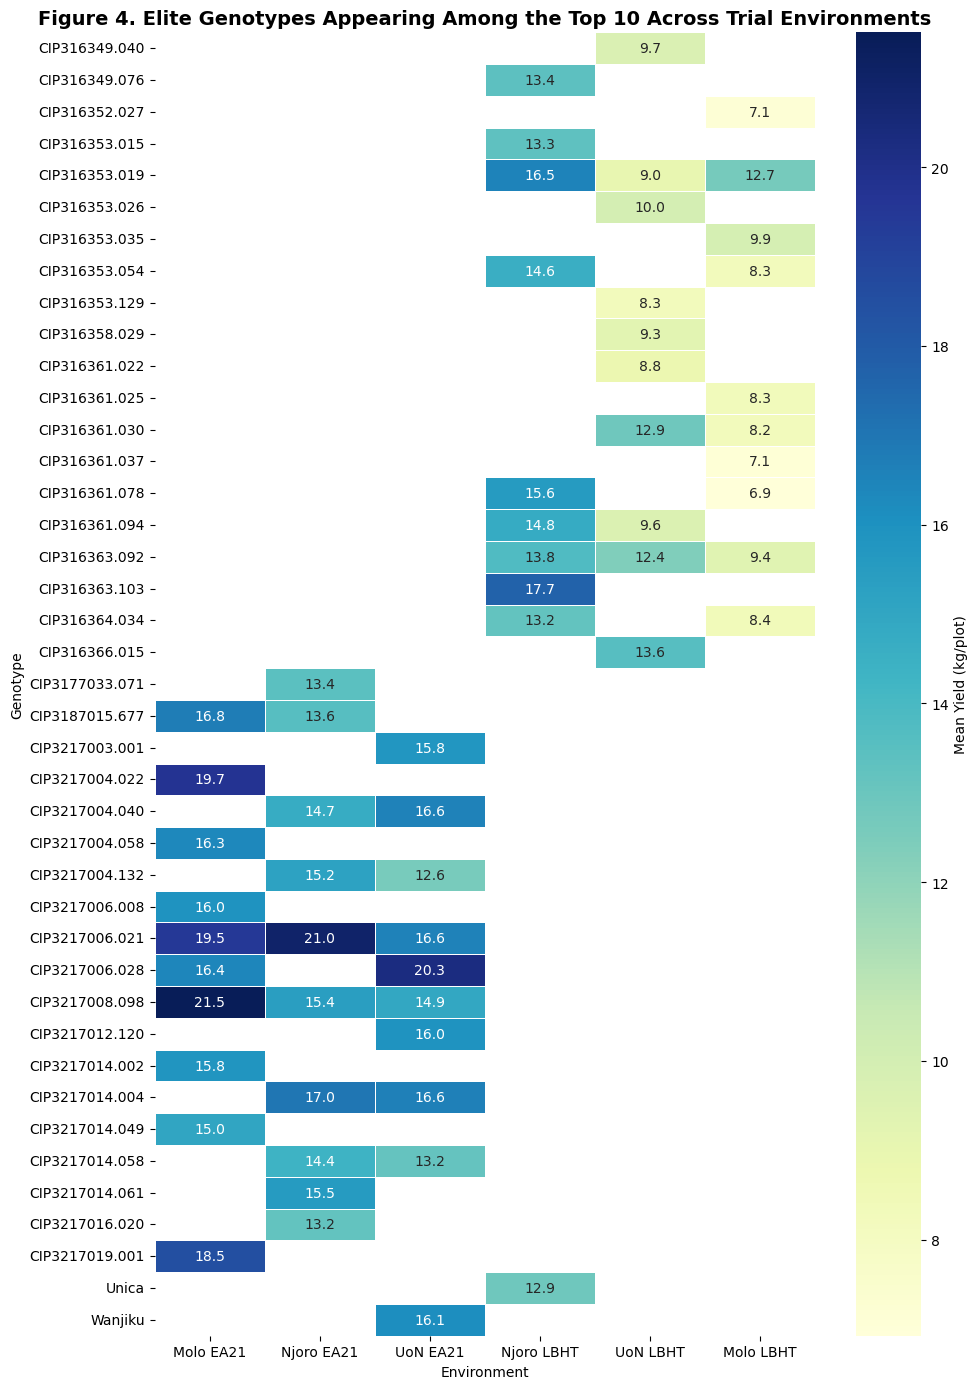

In [124]:
# ==========================================================
# Figure 4
# Cross-Environment Consistency of Elite Yielding Genotypes
# ==========================================================

import seaborn as sns
import matplotlib.pyplot as plt

heat = (
    top10
    .pivot_table(
        index="geno",
        columns="Environment",
        values="Mean_Yield_kg",
        aggfunc="mean"
    )
)

# Order columns
heat = heat[
    [
        "Molo EA21",
        "Njoro EA21",
        "UoN EA21",
        "Njoro LBHT",
        "UoN LBHT",
        "Molo LBHT"
    ]
]

plt.figure(figsize=(10,14))

sns.heatmap(
    heat,
    cmap="YlGnBu",
    linewidths=0.5,
    annot=True,
    fmt=".1f",
    cbar_kws={
        "label":"Mean Yield (kg/plot)"
    }
)

plt.title(
    "Figure 4. Elite Genotypes Appearing Among the Top 10 Across Trial Environments",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Environment")
plt.ylabel("Genotype")

plt.tight_layout()

plt.savefig(
    "Figure4_Elite_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Figure 4 identifies genotypes that repeatedly ranked among the ten highest-yielding entries across the six trial environments. Rather than highlighting single-environment winners, this analysis reveals breeding clones exhibiting consistent superior performance under comparable production conditions.

Within the EA21 trials, **CIP3217006.021** and **CIP3217008.098** were the only genotypes to appear among the top ten performers in all three environments (Molo, Njoro and UoN), demonstrating broad adaptation under favourable production conditions. Although absolute yield differed among sites, both clones consistently maintained superior rankings, indicating stable expression of high yield potential.

A similar pattern was observed within the late blight hotspot trials, where **CIP316353.019** and **CIP316363.092** consistently ranked among the top-performing genotypes across all three disease hotspot environments. These clones maintained competitive yield despite environments expected to impose substantial disease pressure, suggesting potential tolerance or resilience under stress conditions.

The limited overlap between elite performers in EA21 and LBHT environments indicates that genotype performance is strongly influenced by environmental conditions. This observation provides preliminary evidence for genotype × environment interaction and supports the need for mixed-model analyses to quantify genotype stability and identify broadly adapted breeding material.

**Key Takeaways**

- Two genotypes (CIP3217006.021 and CIP3217008.098) consistently ranked among the top ten in all three EA21 environments.
- Two different genotypes (CIP316353.019 and CIP316363.092) consistently ranked among the top ten in all three LBHT environments.
- Elite genotype composition differed between favourable and disease hotspot environments.
- These findings provide preliminary evidence of genotype × environment interaction and identify candidate clones for further evaluation using spatial mixed models.

In [125]:
master_clean.loc[
    master_clean["geno"].str.contains("Shangi", case=False, na=False),
    ["trial", "geno", "weight_g_total"]
].head(20)

,trial,geno,weight_g_total
10,KE25MOL-EA21-AT01_table-Final,Shangi,10701.3
15,KE25MOL-EA21-AT01_table-Final,Shangi,7333.0
42,KE25MOL-EA21-AT01_table-Final,Shangi,13389.5
106,KE25MOL-EA21-AT01_table-Final,Shangi,16278.6
138,KE25MOL-EA21-AT01_table-Final,Shangi,12555.1
167,KE25MOL-EA21-AT01_table-Final,Shangi,11101.4
213,KE25MOL-LBHT-IT01_table-Final,Shangi,4880.6
246,KE25MOL-LBHT-IT01_table-Final,Shangi,3526.2
293,KE25MOL-LBHT-IT01_table-Final,Shangi,5616.1
355,KE25MOL-LBHT-IT01_table-Final,Shangi,6818.7


In [126]:
print(sorted(master_clean["geno"].dropna().unique()))

['CIP312010.759', 'CIP312079.001', 'CIP312079.002', 'CIP312079.003', 'CIP312079.004', 'CIP312079.006', 'CIP312079.008', 'CIP312079.009', 'CIP312079.010', 'CIP312079.011', 'CIP312079.012', 'CIP312084.731', 'CIP315360.117', 'CIP316348.047', 'CIP316348.096', 'CIP316349.006', 'CIP316349.017', 'CIP316349.030', 'CIP316349.031', 'CIP316349.032', 'CIP316349.040', 'CIP316349.066', 'CIP316349.070', 'CIP316349.076', 'CIP316349.102', 'CIP316349.121', 'CIP316349.128', 'CIP316349.134', 'CIP316349.140', 'CIP316349.141', 'CIP316352.008', 'CIP316352.027', 'CIP316352.076', 'CIP316353.015', 'CIP316353.019', 'CIP316353.026', 'CIP316353.030', 'CIP316353.035', 'CIP316353.048', 'CIP316353.054', 'CIP316353.058', 'CIP316353.059', 'CIP316353.104', 'CIP316353.128', 'CIP316353.129', 'CIP316354.164', 'CIP316354.165', 'CIP316355.037', 'CIP316355.041', 'CIP316356.023', 'CIP316357.016', 'CIP316357.059', 'CIP316357.067', 'CIP316357.070', 'CIP316358.029', 'CIP316358.055', 'CIP316358.069', 'CIP316358.070', 'CIP316358.13

In [127]:
sorted(
    master_clean.loc[
        ~master_clean["geno"].str.startswith("CIP", na=False),
        "geno"
    ].dropna().unique()
)

['NARI002',
 'NARI004',
 'NARI005',
 'Sagitta',
 'Shangi',
 'Sherekea',
 'Unica',
 'Wanjiku',
 'dummy-Shangi',
 'dummy-Sherekea']

In [128]:
geno_rank.loc[
    geno_rank["geno"] == "Shangi"
].sort_values("Mean_Yield_kg", ascending=False)

,trial,geno,Mean_Yield,Median_Yield,SD,Plots,Mean_Yield_kg,Environment
55,KE25MOL-EA21-AT01_table-Final,Shangi,11893.150000,11828.25,2991.713734,6,11.893150,Molo EA21
230,KE25NJO-EA21-AT01_table-Final,Shangi,9046.666667,8420.00,1876.407916,6,9.046667,Njoro EA21
343,KE25NJO-LBHT-IT01_table-Final,Shangi,8980.720000,8533.70,1393.753026,5,8.980720,Njoro LBHT
173,KE25MOL-LBHT-IT01_table-Final,Shangi,4947.500000,4733.15,1147.144976,6,4.947500,Molo LBHT
399,KE25UON-EA21-AT01_table-Final,Shangi,3904.966667,2636.60,2931.892260,3,3.904967,UoN EA21
521,KE25UON-LBHT-IT01_table-Final,Shangi,3851.350000,3851.35,144.461915,2,3.851350,UoN LBHT


In [129]:
master_clean.loc[
    master_clean["geno"].str.contains("dummy", case=False, na=False),
    ["trial", "geno", "entry", "row", "column", "weight_g_total"]
].head(30)

,trial,geno,entry,row,column,weight_g_total
907,KE25UON-EA21-AT01_table-Final,dummy-Shangi,56,12,2,NaN
917,KE25UON-EA21-AT01_table-Final,dummy-Shangi,56,2,3,NaN
936,KE25UON-EA21-AT01_table-Final,dummy-Sherekea,55,1,4,NaN
972,KE25UON-EA21-AT01_table-Final,dummy-Shangi,56,17,5,NaN
973,KE25UON-EA21-AT01_table-Final,dummy-Sherekea,55,18,5,NaN
988,KE25UON-EA21-AT01_table-Final,dummy-Sherekea,55,13,6,NaN


In [130]:
# ==========================================================
# Final Dataset Used for All Subsequent Analyses
# ==========================================================

master_clean = master_clean.loc[
    ~master_clean["geno"].str.contains("dummy", case=False, na=False)
].copy()

print(f"Final dataset: {master_clean.shape}")

Final dataset: (1314, 122)


# SECTION 3.3: Commercial Checks vs. Elite Breeding Clones
### Scientific Question

How do the commercial check varieties compare with the breeding population across trial environments?

In [131]:
# ==========================================================
# SECTION 3.3
# Classify Genotypes
# ==========================================================

# Named commercial checks
checks = [
    "Shangi",
    "Unica",
    "Wanjiku",
    "Sagitta",
    "Sherekea",
    "NARI002",
    "NARI004",
    "NARI005"
]

master_clean["Genotype_Type"] = np.where(
    master_clean["geno"].isin(checks),
    "Commercial Check",
    "Breeding Clone"
)

master_clean["Genotype_Type"].value_counts()

Genotype_Type
Breeding Clone      1209
Commercial Check     105
Name: count, dtype: int64

In [132]:
master_clean.loc[
    master_clean["Genotype_Type"] == "Commercial Check",
    "geno"
].drop_duplicates().sort_values()

34       NARI002
23       NARI004
1019     NARI005
8        Sagitta
10        Shangi
43      Sherekea
21         Unica
457      Wanjiku
Name: geno, dtype: category
Categories (191, str): ['CIP312010.759', 'CIP312079.001', 'CIP312079.002', 'CIP312079.003', ..., 'Unica', 'Wanjiku', 'dummy-Shangi', 'dummy-Sherekea']

In [133]:
# ==========================================================
# Performance of Commercial Checks
# ==========================================================

check_summary = (
    master_clean
    .loc[master_clean["Genotype_Type"] == "Commercial Check"]
    .groupby(
        ["trial", "geno"],
        observed=True
    )
    .agg(
        Mean_Yield=("weight_g_total", "mean"),
        Median=("weight_g_total", "median"),
        SD=("weight_g_total", "std"),
        Plots=("weight_g_total", "count")
    )
    .reset_index()
)

check_summary["Mean_Yield_kg"] = (
    check_summary["Mean_Yield"] / 1000
)

check_summary["Environment"] = (
    check_summary["trial"]
    .map(trial_map)
)

check_summary = check_summary.sort_values(
    ["Environment", "Mean_Yield_kg"],
    ascending=[True, False]
)

check_summary

,trial,geno,Mean_Yield,Median,SD,Plots,Mean_Yield_kg,Environment
3,KE25MOL-EA21-AT01_table-Final,Shangi,11893.150000,11828.25,2991.713734,6,11.893150,Molo EA21
1,KE25MOL-EA21-AT01_table-Final,NARI004,6386.566667,6927.10,1306.539036,3,6.386567,Molo EA21
2,KE25MOL-EA21-AT01_table-Final,Sagitta,2262.700000,2636.70,710.874701,3,2.262700,Molo EA21
5,KE25MOL-EA21-AT01_table-Final,Unica,1740.933333,1825.10,319.086890,3,1.740933,Molo EA21
0,KE25MOL-EA21-AT01_table-Final,NARI002,799.366667,843.70,178.966822,3,0.799367,Molo EA21
...,...,...,...,...,...,...,...,...
33,KE25UON-LBHT-IT01_table-Final,Wanjiku,7689.250000,7479.05,2668.256827,4,7.689250,UoN LBHT
29,KE25UON-LBHT-IT01_table-Final,Sagitta,4791.450000,4791.45,1523.602981,2,4.791450,UoN LBHT
32,KE25UON-LBHT-IT01_table-Final,Unica,4181.900000,4181.90,4407.679410,2,4.181900,UoN LBHT
30,KE25UON-LBHT-IT01_table-Final,Shangi,3851.350000,3851.35,144.461915,2,3.851350,UoN LBHT


### Interpretation

The commercial check varieties exhibited substantial variation in yield across environments, indicating marked differences in their adaptation to the diverse trial conditions. Shangi consistently emerged as the highest-yielding commercial check in the favourable Molo EA21 environment, achieving a mean yield of **11.89 kg per plot**, substantially outperforming the other check varieties evaluated at the same site.

Performance of the commercial checks varied considerably across environments. While Shangi remained competitive in several trials, its performance declined markedly in the UoN environments, particularly under the EA21 trial where the mean yield decreased to **3.90 kg per plot**. Conversely, Wanjiku exhibited superior performance in the UoN LBHT environment, recording the highest mean yield (**7.69 kg per plot**) among the commercial checks at that location.

The variation in check performance across environments suggests considerable environmental influence on genotype expression and indicates that no single commercial variety consistently dominated all testing sites. This reinforces the importance of multi-environment testing when evaluating candidate breeding lines against commercial standards.

These commercial check means provide an essential benchmark against which the performance gains achieved by elite breeding clones can be quantified.

**Key Takeaways**

- Commercial check performance differed substantially among environments.
- Shangi was the highest-yielding check in Molo EA21 but was not consistently superior across all sites.
- Wanjiku performed particularly well in the UoN LBHT environment.
- No commercial variety consistently ranked among the highest-yielding entries across all environments.
- Commercial checks establish the baseline for evaluating the genetic gain achieved by elite breeding clones.

In [134]:
# ==========================================================
# Best Commercial Check per Environment
# ==========================================================

best_check = (
    check_summary
    .sort_values(
        ["Environment", "Mean_Yield_kg"],
        ascending=[True, False]
    )
    .groupby("Environment", observed=True)
    .head(1)
    .reset_index(drop=True)
)

best_check = best_check[[
    "Environment",
    "geno",
    "Mean_Yield_kg",
    "Plots"
]]

best_check = best_check.rename(columns={
    "geno": "Best_Check",
    "Mean_Yield_kg": "Check_Yield_kg"
})

best_check

,Environment,Best_Check,Check_Yield_kg,Plots
0,Molo EA21,Shangi,11.893150,6
1,Molo LBHT,Shangi,4.947500,6
2,Njoro EA21,Sagitta,12.346667,3
3,Njoro LBHT,Unica,12.865750,4
4,UoN EA21,Wanjiku,16.096900,4
5,UoN LBHT,Wanjiku,7.689250,4


In [135]:
# ==========================================================
# Best Breeding Clone per Environment
# ==========================================================

best_clone = (
    geno_rank
    .sort_values(
        ["Environment", "Mean_Yield_kg"],
        ascending=[True, False]
    )
    .groupby("Environment", observed=True)
    .head(1)
    .reset_index(drop=True)
)

best_clone = best_clone[[
    "Environment",
    "geno",
    "Mean_Yield_kg"
]]

best_clone = best_clone.rename(columns={
    "geno": "Best_Clone",
    "Mean_Yield_kg": "Clone_Yield_kg"
})

best_clone

,Environment,Best_Clone,Clone_Yield_kg
0,Molo EA21,CIP3217008.098,21.509100
1,Molo LBHT,CIP316353.019,12.672650
2,Njoro EA21,CIP3217006.021,20.966667
3,Njoro LBHT,CIP316363.103,17.717550
4,UoN EA21,CIP3217006.028,20.280267
5,UoN LBHT,CIP316366.015,13.568250


In [136]:
# ==========================================================
# Elite Clone vs Best Commercial Check
# ==========================================================

comparison = (
    best_clone
    .merge(best_check, on="Environment")
)

comparison["Yield_Advantage_%"] = (
    (comparison["Clone_Yield_kg"] - comparison["Check_Yield_kg"])
    / comparison["Check_Yield_kg"] * 100
).round(1)

comparison = comparison[[
    "Environment",
    "Best_Clone",
    "Clone_Yield_kg",
    "Best_Check",
    "Check_Yield_kg",
    "Yield_Advantage_%"
]]

comparison

,Environment,Best_Clone,Clone_Yield_kg,Best_Check,Check_Yield_kg,Yield_Advantage_%
0,Molo EA21,CIP3217008.098,21.509100,Shangi,11.893150,80.9
1,Molo LBHT,CIP316353.019,12.672650,Shangi,4.947500,156.1
2,Njoro EA21,CIP3217006.021,20.966667,Sagitta,12.346667,69.8
3,Njoro LBHT,CIP316363.103,17.717550,Unica,12.865750,37.7
4,UoN EA21,CIP3217006.028,20.280267,Wanjiku,16.096900,26.0
5,UoN LBHT,CIP316366.015,13.568250,Wanjiku,7.689250,76.5


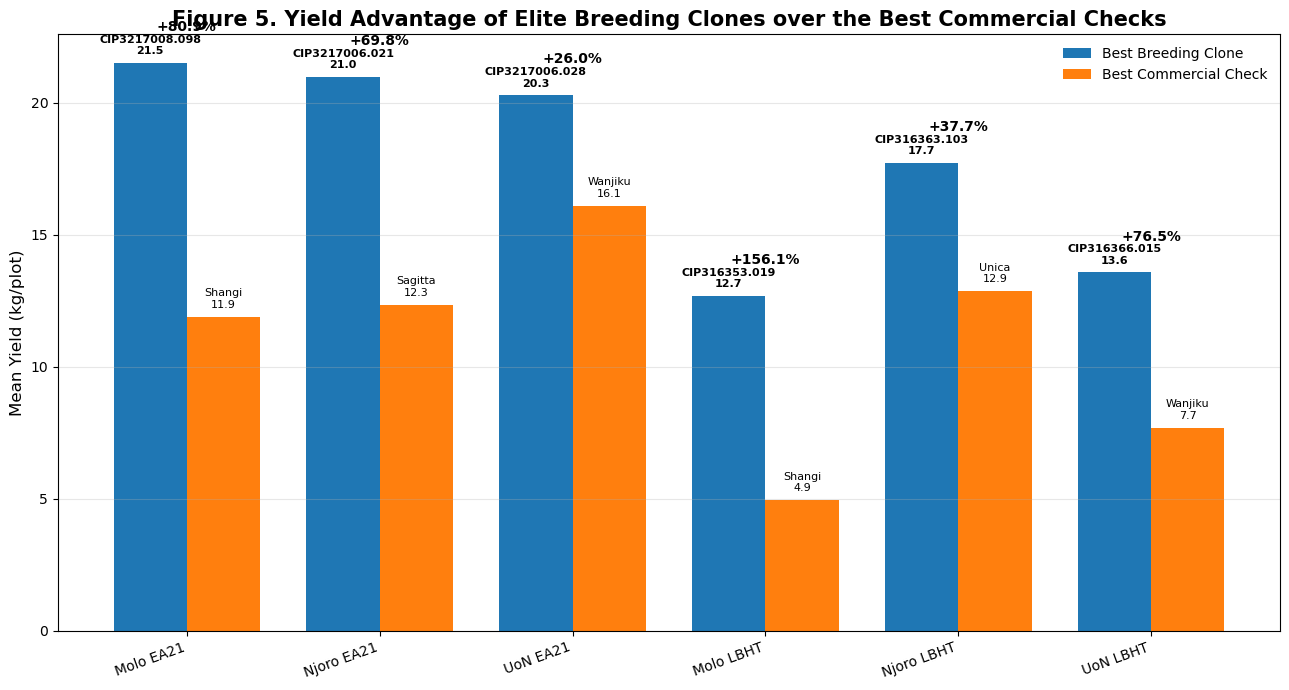

In [137]:
# ==========================================================
# Figure 5
# Elite Breeding Clone vs Best Commercial Check
# ==========================================================

import matplotlib.pyplot as plt
import numpy as np

# Sort environments in logical order
env_order = [
    "Molo EA21",
    "Njoro EA21",
    "UoN EA21",
    "Molo LBHT",
    "Njoro LBHT",
    "UoN LBHT"
]

comparison_plot = (
    comparison
    .set_index("Environment")
    .loc[env_order]
    .reset_index()
)

x = np.arange(len(comparison_plot))
width = 0.38

fig, ax = plt.subplots(figsize=(13,7))

# ---------------------------------------------------------
# Bars
# ---------------------------------------------------------

bars1 = ax.bar(
    x - width/2,
    comparison_plot["Clone_Yield_kg"],
    width,
    label="Best Breeding Clone"
)

bars2 = ax.bar(
    x + width/2,
    comparison_plot["Check_Yield_kg"],
    width,
    label="Best Commercial Check"
)

# ---------------------------------------------------------
# Labels for breeding clones
# ---------------------------------------------------------

for i, row in comparison_plot.iterrows():

    ax.text(
        i - width/2,
        row["Clone_Yield_kg"] + 0.25,
        f"{row['Best_Clone']}\n{row['Clone_Yield_kg']:.1f}",
        ha="center",
        va="bottom",
        fontsize=8,
        fontweight="bold"
    )

# ---------------------------------------------------------
# Labels for commercial checks
# ---------------------------------------------------------

for i, row in comparison_plot.iterrows():

    ax.text(
        i + width/2,
        row["Check_Yield_kg"] + 0.25,
        f"{row['Best_Check']}\n{row['Check_Yield_kg']:.1f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

# ---------------------------------------------------------
# Percentage advantage
# ---------------------------------------------------------

for i, row in comparison_plot.iterrows():

    ymax = max(
        row["Clone_Yield_kg"],
        row["Check_Yield_kg"]
    )

    ax.text(
        i,
        ymax + 1.2,
        f"+{row['Yield_Advantage_%']:.1f}%",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

# ---------------------------------------------------------
# Formatting
# ---------------------------------------------------------

ax.set_xticks(x)
ax.set_xticklabels(
    comparison_plot["Environment"],
    rotation=20,
    ha="right"
)

ax.set_ylabel("Mean Yield (kg/plot)", fontsize=12)

ax.set_title(
    "Figure 5. Yield Advantage of Elite Breeding Clones over the Best Commercial Checks",
    fontsize=15,
    fontweight="bold"
)

ax.legend(frameon=False)

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "Figure5_Elite_vs_Checks.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Comparison of the highest-yielding breeding clones with the best-performing commercial checks demonstrated substantial genetic gain across all six trial environments. In every environment, the leading breeding clone exceeded the highest-yielding commercial variety, although the magnitude of superiority varied considerably.

The greatest improvement was observed in the **Molo LBHT** environment, where **CIP316353.019** outperformed the best commercial check (Shangi) by **156.1%**, indicating exceptional performance under late blight hotspot conditions. Similarly, breeding clones achieved yield advantages of **80.9%** in Molo EA21 and **76.5%** in UoN LBHT, highlighting their strong potential under both favourable and disease-prone environments.

More moderate, yet still substantial, advantages were recorded in **Njoro EA21 (69.8%)**, **Njoro LBHT (37.7%)**, and **UoN EA21 (26.0%)**. These results demonstrate that although commercial checks remained competitive in some environments, the elite breeding clones consistently provided measurable yield improvements.

Interestingly, the highest-performing commercial check differed among environments. Shangi served as the strongest benchmark in the Molo trials, whereas Sagitta, Unica and Wanjiku emerged as the highest-yielding checks in Njoro EA21, Njoro LBHT and the University of Nairobi trials, respectively. This further illustrates the strong influence of environmental conditions on genotype performance.

Overall, the consistent superiority of the elite breeding clones provides strong evidence that the breeding programme has generated germplasm with substantial yield advantages over currently available commercial varieties.

### Interpretation 2

Figure 5 compares the highest-yielding elite breeding clone with the best-performing commercial check in each trial environment. Across all six environments, the leading breeding clone consistently exceeded the yield of the highest-performing commercial variety, demonstrating substantial genetic gain from the breeding programme.

In the **EA21 environments**, the elite clones **CIP3217008.098**, **CIP3217006.021**, and **CIP3217006.028** produced the highest yields, ranging from **20.3 to 21.5 kg per plot**. These clones outperformed the best commercial checks by **26.0–80.9%**, indicating excellent performance under favourable production conditions.

Under the **late blight hotspot (LBHT) environments**, a different group of elite clones emerged as the highest performers. **CIP316353.019**, **CIP316363.103**, and **CIP316366.015** consistently surpassed the best commercial checks by **37.7–156.1%**. The largest yield advantage was observed in **Molo LBHT**, where **CIP316353.019** produced **12.7 kg per plot**, exceeding Shangi by **156.1%**. This exceptional advantage suggests strong adaptation of this clone under severe disease pressure.

The identity of the best commercial check varied among environments. **Shangi** was the strongest benchmark in the Molo trials, **Sagitta** performed best in Njoro EA21, **Unica** ranked highest in Njoro LBHT, while **Wanjiku** was the leading commercial variety in both University of Nairobi environments. This variation demonstrates the importance of genotype × environment interaction and indicates that no single commercial cultivar was universally superior.

Overall, the consistent superiority of elite breeding clones across all environments provides strong evidence that the breeding programme has generated high-yielding germplasm with clear advantages over currently cultivated commercial varieties.

**Key Takeaways**

- The highest-yielding breeding clone outperformed the best commercial check in every environment.
- Yield advantages ranged from **26.0%** to **156.1%**, depending on the testing environment.
- The largest genetic gain was observed under late blight hotspot conditions.
- Different commercial checks served as the benchmark in different environments, highlighting genotype × environment interactions.
- Several elite breeding clones demonstrated sufficient yield superiority to warrant further evaluation in advanced breeding stages.

## This is my next roadmap

4. Yield Component Analysis

4.1 Total tuber number

4.2 Tuber size distribution

4.3 Yield contribution by size class

4.4 Marketable yield

4.5 Yield component relationships

4.6 Correlation analysis

# ============================================================
# 4. Yield Component Analysis
# ============================================================

## 4.1 Total Tuber Number

In [138]:
# ==========================================================
# Total tuber number by environment
# ==========================================================

tuber_summary = (
    master_clean
    .groupby("trial", observed=True)
    .agg(
        Plots=("calculated_total_count", "count"),
        Mean_Tubers=("calculated_total_count", "mean"),
        Median=("calculated_total_count", "median"),
        SD=("calculated_total_count", "std"),
        Minimum=("calculated_total_count", "min"),
        Maximum=("calculated_total_count", "max")
    )
    .reset_index()
)

tuber_summary["Environment"] = (
    tuber_summary["trial"]
    .map(trial_map)
)

tuber_summary = tuber_summary[
    [
        "Environment",
        "Plots",
        "Mean_Tubers",
        "Median",
        "SD",
        "Minimum",
        "Maximum"
    ]
]

tuber_summary

,Environment,Plots,Mean_Tubers,Median,SD,Minimum,Maximum
0,Molo EA21,174,135.275862,134.5,60.133414,0.0,299.0
1,Molo LBHT,264,48.825758,44.0,29.475774,0.0,194.0
2,Njoro EA21,174,0.000000,0.0,0.000000,0.0,0.0
3,Njoro LBHT,264,73.890152,68.0,42.172100,0.0,271.0
4,UoN EA21,174,96.419540,87.5,67.951631,0.0,321.0
5,UoN LBHT,264,63.666667,62.0,32.008000,0.0,216.0


- Molo EA21	- Highest tuber production, indicating excellent growing conditions and strong genotype performance.
- UoN EA21	- Second highest tuber number but with greater variability among genotypes.
- Njoro LBHT	- Highest tuber number under disease pressure, suggesting relatively favorable adaptation despite late blight.
- UoN LBHT	- Moderate tuber production with acceptable consistency.
- Molo LBHT	- Lowest tuber production among the hotspot environments, indicating stronger disease or environmental stress.
- Njoro EA21	- Values are invalid because tuber counts were not recorded and should not be interpreted biologically.

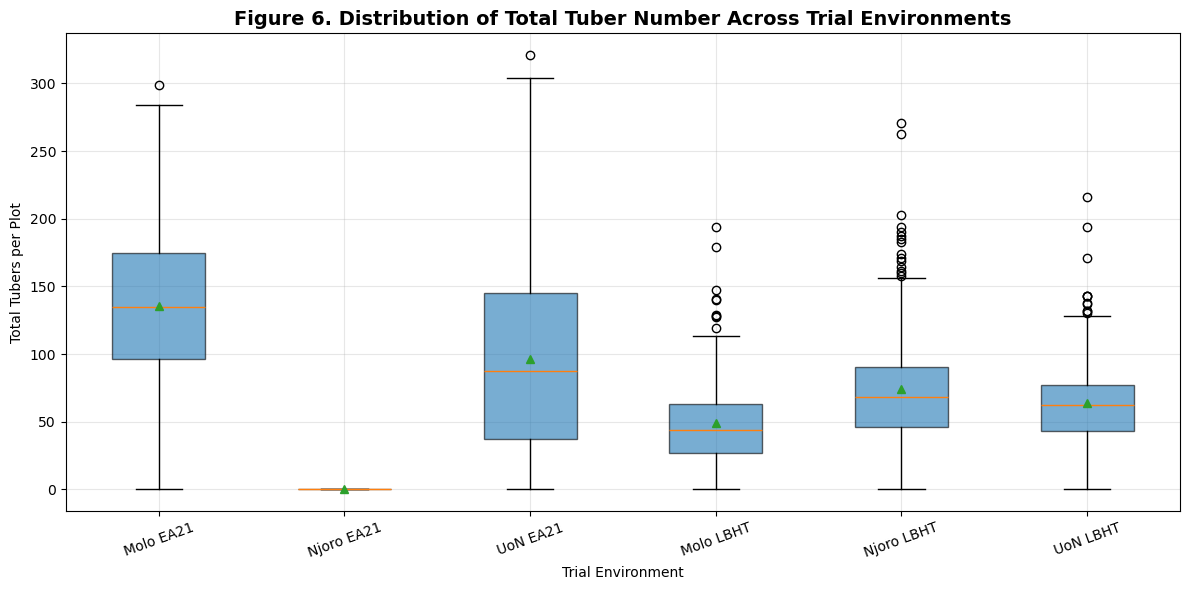

In [139]:
# ==========================================================
# Figure 6
# Distribution of Total Tuber Number
# ==========================================================

plot_df = master_clean.copy()

plot_df["Environment"] = (
    plot_df["trial"]
    .map(trial_map)
)

env_order = [
    "Molo EA21",
    "Njoro EA21",
    "UoN EA21",
    "Molo LBHT",
    "Njoro LBHT",
    "UoN LBHT"
]

fig, ax = plt.subplots(figsize=(12,6))

bp = ax.boxplot(
    [
        plot_df.loc[
            plot_df["Environment"] == env,
            "calculated_total_count"
        ].dropna()
        for env in env_order
    ],
    tick_labels=env_order,
    patch_artist=True,
    showmeans=True
)

for box in bp["boxes"]:
    box.set_alpha(0.6)

ax.set_ylabel("Total Tubers per Plot")

ax.set_xlabel("Trial Environment")

ax.set_title(
    "Figure 6. Distribution of Total Tuber Number Across Trial Environments",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(rotation=20)

ax.grid(alpha=0.3)

plt.tight_layout()

plt.show()

# Interpretation
#### Figure 6. Distribution of Total Tuber Number Across Trial Environments

Figure 6 illustrates the distribution of total tuber number per plot across the six trial environments.

Among the environments where tuber counts were recorded, Molo EA21 produced the highest tuber numbers, with an average of 135 tubers per plot and individual plots producing up to 299 tubers. This indicates a highly productive environment that supported prolific tuber formation.

UoN EA21 also exhibited relatively high tuber production (mean = 96 tubers per plot), although the larger spread of observations suggests greater variability among genotypes.

Within the late blight hotspot environments, Njoro LBHT recorded the highest average tuber number (74 tubers per plot), followed by UoN LBHT (64 tubers) and Molo LBHT (49 tubers). These lower tuber counts relative to the EA21 environments are consistent with the expected reduction in tuber production under disease pressure.

The boxplots further demonstrate considerable genotype-to-genotype variation within each environment, particularly in the EA21 trials, where several high-performing genotypes produced exceptionally large numbers of tubers.

The Njoro EA21 environment recorded zero tubers for every plot. Since this environment simultaneously produced normal total yield values, these zeros most likely represent missing observations rather than true biological measurements. Consequently, Njoro EA21 should be excluded from analyses involving tuber number.

# ==========================================================
# SECTION 7: GENOTYPE × ENVIRONMENT PERFORMANCE
# ==========================================================

### Average yield of every genotype

In [140]:
geno_overall = (
    master_clean
    .dropna(subset=["weight_g_total"])
    .groupby("geno", observed=False)
    .agg(
        Environments=("trial","nunique"),
        Observations=("weight_g_total","count"),
        Mean_Yield=("weight_g_total","mean"),
        Median=("weight_g_total","median"),
        SD=("weight_g_total","std")
    )
    .reset_index()
)

geno_overall["Mean_Yield_kg"] = (
    geno_overall["Mean_Yield"]/1000
)

geno_overall = geno_overall.sort_values(
    "Mean_Yield_kg",
    ascending=False
)

geno_overall.head(20)

,geno,Environments,Observations,Mean_Yield,Median,SD,Mean_Yield_kg
148,CIP3217006.021,3,9,19008.466667,18640.00,3569.917338,19.008467
155,CIP3217008.098,3,9,17272.177778,17400.10,7034.244905,17.272178
159,CIP3217014.004,3,9,15698.533333,16235.30,2516.190936,15.698533
139,CIP3217004.040,3,12,15427.225000,15084.95,2874.117726,15.427225
144,CIP3217004.132,3,9,14041.555556,13944.80,5472.293052,14.041556
137,CIP3217004.022,3,9,13474.122222,15248.70,7181.530198,13.474122
149,CIP3217006.028,3,9,12823.800000,14760.30,8870.368464,12.823800
157,CIP3217012.120,3,10,12594.010000,12450.65,2948.953291,12.594010
180,CIP3217019.104,1,1,12495.000000,12495.00,NaN,12.495000
132,CIP3187015.677,3,8,12297.262500,12915.15,6357.026125,12.297263


### Overall Performance of Genotypes Across Environments

To identify broadly adapted breeding materials, mean tuber yield was calculated for each genotype across all environments where it was evaluated. This analysis differs from the environment-specific rankings by assessing the overall productivity of each genotype throughout the multi-environment trial.

The results demonstrate that several elite breeding clones consistently achieved high mean yields across environments. The highest-ranked genotype was CIP3217006.021, with an average yield of 19.01 kg per plot, followed by CIP3217008.098 (17.27 kg per plot) and CIP3217014.004 (15.70 kg per plot). These genotypes maintained high productivity across all three EA21 environments, indicating broad adaptation under non-late blight conditions.

Several additional breeding lines, including CIP3217004.040, CIP3217004.132, CIP3217004.022, CIP3217006.028, and CIP3217012.120, also produced mean yields exceeding 12 kg per plot, substantially outperforming most commercial checks.

Among the commercial varieties, Wanjiku ranked as the highest-performing check with a mean yield of 11.79 kg per plot, demonstrating good adaptation across multiple environments. However, several elite breeding clones exceeded Wanjiku by more than 20–60%, highlighting the significant genetic gains achieved through the breeding program.

The predominance of the CIP3217 breeding population among the highest-yielding genotypes suggests that this genetic background contains several promising candidates for advancement into regional performance trials and potential variety release.

finding out how many environments was each genotype evaluated in

In [141]:
geno_overall["Environments"].value_counts().sort_index()

Environments
0      5
1     15
2     20
3    147
6      4
Name: count, dtype: int64

keeping only broadly tested genotypes

In [142]:
stable_candidates = geno_overall.loc[
    geno_overall["Environments"] >= 3
].copy()

stable_candidates = stable_candidates.sort_values(
    "Mean_Yield_kg",
    ascending=False
)

stable_candidates.head(20)

,geno,Environments,Observations,Mean_Yield,Median,SD,Mean_Yield_kg
148,CIP3217006.021,3,9,19008.466667,18640.00,3569.917338,19.008467
155,CIP3217008.098,3,9,17272.177778,17400.10,7034.244905,17.272178
159,CIP3217014.004,3,9,15698.533333,16235.30,2516.190936,15.698533
139,CIP3217004.040,3,12,15427.225000,15084.95,2874.117726,15.427225
144,CIP3217004.132,3,9,14041.555556,13944.80,5472.293052,14.041556
137,CIP3217004.022,3,9,13474.122222,15248.70,7181.530198,13.474122
149,CIP3217006.028,3,9,12823.800000,14760.30,8870.368464,12.823800
157,CIP3217012.120,3,10,12594.010000,12450.65,2948.953291,12.594010
132,CIP3187015.677,3,8,12297.262500,12915.15,6357.026125,12.297263
167,CIP3217014.143,3,9,12109.477778,12780.00,5528.164254,12.109478


### **Interpretation**

### Overall Genotype Performance Across Environments

To identify breeding materials with broad adaptation, the mean tuber yield of each genotype was calculated across all environments in which it was evaluated. Only genotypes evaluated in at least three environments were considered for ranking to ensure reliable comparisons.

The analysis revealed substantial differences in overall productivity among genotypes. The highest yielding genotype was CIP3217006.021, with a mean yield of 19.01 kg plot⁻¹, followed by CIP3217008.098 (17.27 kg plot⁻¹) and CIP3217014.004 (15.70 kg plot⁻¹). Several additional breeding clones from the CIP3217 population also ranked among the highest-performing materials, demonstrating consistently superior performance across multiple environments.

Among the commercial checks, Wanjiku was the highest-performing variety, with a mean yield of 11.79 kg plot⁻¹, ranking fifteenth overall. The presence of numerous breeding clones above the best commercial check indicates considerable genetic gain achieved through the breeding program.

The dominance of the CIP3217 breeding family among the highest-ranked genotypes suggests that this population possesses broad adaptation and high yield potential across diverse environments.

In [143]:
# ==========================================================
# Genotype Stability Statistics
# ==========================================================

stability = (
    master_clean
    .dropna(subset=["weight_g_total"])
    .groupby("geno", observed=False)
    .agg(
        Mean=("weight_g_total","mean"),
        SD=("weight_g_total","std"),
        Environments=("trial","nunique"),
        Observations=("weight_g_total","count")
    )
    .reset_index()
)

stability["Mean_kg"] = stability["Mean"] / 1000

stability["CV"] = (
    stability["SD"] /
    stability["Mean"] * 100
)

stability = stability[
    stability["Environments"] >= 3
].copy()

stability.head()

,geno,Mean,SD,Environments,Observations,Mean_kg,CV
0,CIP312010.759,9119.40,2246.788180,3,9,9.11940,24.637456
1,CIP312079.001,5546.00,2227.647432,3,5,5.54600,40.166741
5,CIP312079.006,6751.66,3294.079763,3,5,6.75166,48.789183
6,CIP312079.008,2779.78,1668.069503,3,5,2.77978,60.007249
7,CIP312079.009,5633.76,4544.311702,3,5,5.63376,80.662146


In [144]:
checks = [
    "Shangi",
    "Sherekea",
    "Unica",
    "Wanjiku",
    "Sagitta",
    "NARI002",
    "NARI004",
    "NARI005"
]

stability["Type"] = np.where(
    stability["geno"].isin(checks),
    "Commercial Check",
    "Elite Clone"
)

stability.head()

,geno,Mean,SD,Environments,Observations,Mean_kg,CV,Type
0,CIP312010.759,9119.40,2246.788180,3,9,9.11940,24.637456,Elite Clone
1,CIP312079.001,5546.00,2227.647432,3,5,5.54600,40.166741,Elite Clone
5,CIP312079.006,6751.66,3294.079763,3,5,6.75166,48.789183,Elite Clone
6,CIP312079.008,2779.78,1668.069503,3,5,2.77978,60.007249,Elite Clone
7,CIP312079.009,5633.76,4544.311702,3,5,5.63376,80.662146,Elite Clone


### Stability of Genotype Performance Across Environments

To evaluate the consistency of genotype performance, the coefficient of variation (CV) of tuber yield was calculated for each genotype across environments. Lower CV values indicate greater yield stability, while higher values reflect stronger genotype × environment interaction.

In [145]:
stability.sort_values(
    "CV"
).head(20)

,geno,Mean,SD,Environments,Observations,Mean_kg,CV,Type
159,CIP3217014.004,15698.533333,2516.190936,3,9,15.698533,16.028191,Elite Clone
139,CIP3217004.040,15427.225000,2874.117726,3,12,15.427225,18.630167,Elite Clone
148,CIP3217006.021,19008.466667,3569.917338,3,9,19.008467,18.780670,Elite Clone
170,CIP3217016.011,7958.288889,1517.117579,3,9,7.958289,19.063364,Elite Clone
95,CIP316363.092,11985.687500,2308.086463,3,8,11.985687,19.257022,Elite Clone
42,CIP316353.104,6534.700000,1272.103666,3,6,6.534700,19.466902,Elite Clone
44,CIP316353.129,7852.550000,1567.060958,3,6,7.852550,19.956077,Elite Clone
73,CIP316361.037,7883.875000,1771.205833,3,8,7.883875,22.466184,Elite Clone
37,CIP316353.035,9500.020000,2138.071680,3,5,9.500020,22.505970,Elite Clone
173,CIP3217016.034,6775.411111,1538.208149,3,9,6.775411,22.702802,Elite Clone


Several elite breeding clones combined high mean yield with low variability, indicating broad adaptation across testing environments. The most stable high-yielding genotype was CIP3217014.004, with a mean yield of 15.70 kg plot⁻¹ and a CV of only 16.0%. Similarly, CIP3217004.040 (15.43 kg plot⁻¹; CV = 18.6%) and CIP3217006.021 (19.01 kg plot⁻¹; CV = 18.8%) demonstrated excellent yield stability while maintaining superior productivity.

Other promising breeding lines, including CIP316363.092, CIP3217012.120, and CIP316361.037, also exhibited relatively low coefficients of variation (<25%), suggesting consistent performance across environments.

Overall, these results indicate that several elite clones possess both high yield potential and broad adaptation, making them strong candidates for advancement to larger regional trials and possible variety release.

- CIP3217006.021 was the highest-yielding genotype overall and remained among the most stable (CV ≈ 19%).
- CIP3217014.004 showed an excellent balance of productivity and stability, which is highly desirable in cultivar development.
- The clustering of several CIP3217 family genotypes among the most stable performers suggests that this breeding population contains valuable genetic material for both high yield and environmental resilience.

# Figure 7. Yield–Stability Relationship of Elite Potato Genotypes

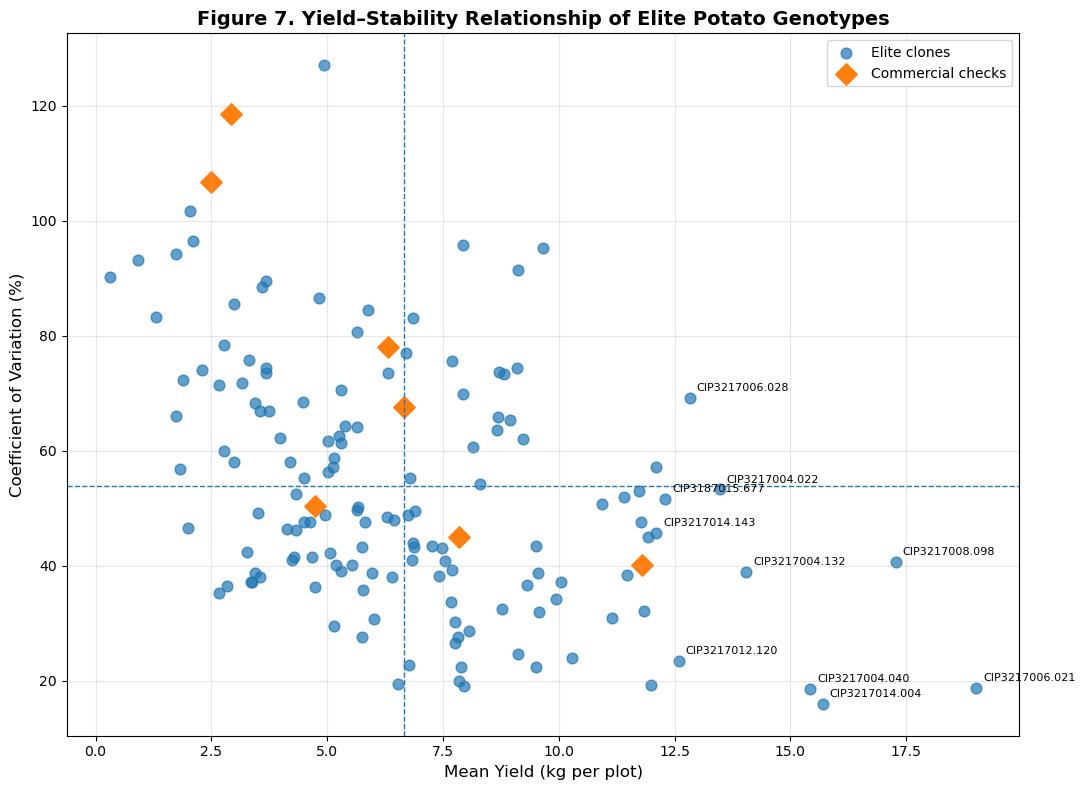

In [146]:
# ==========================================================
# Figure 7. Yield vs Stability
# ==========================================================

fig, ax = plt.subplots(figsize=(11,8))

# Elite clones
elite = stability[stability["Type"] == "Elite Clone"]
checks_df = stability[stability["Type"] == "Commercial Check"]

ax.scatter(
    elite["Mean_kg"],
    elite["CV"],
    s=60,
    alpha=0.7,
    label="Elite clones"
)

ax.scatter(
    checks_df["Mean_kg"],
    checks_df["CV"],
    s=120,
    marker="D",
    label="Commercial checks"
)

# Highlight the 10 highest-yielding genotypes
top10 = stability.nlargest(10, "Mean_kg")

for _, row in top10.iterrows():
    ax.annotate(
        row["geno"],
        (row["Mean_kg"], row["CV"]),
        xytext=(5,5),
        textcoords="offset points",
        fontsize=8
    )

# Mean reference lines
ax.axvline(
    stability["Mean_kg"].mean(),
    linestyle="--",
    linewidth=1
)

ax.axhline(
    stability["CV"].mean(),
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Mean Yield (kg per plot)", fontsize=12)
ax.set_ylabel("Coefficient of Variation (%)", fontsize=12)

ax.set_title(
    "Figure 7. Yield–Stability Relationship of Elite Potato Genotypes",
    fontsize=14,
    fontweight="bold"
)

ax.legend()

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Summary of Exploratory Findings

This notebook integrated phenotypic observations collected across six potato multi-environment trials and performed comprehensive exploratory data analysis to assess data quality, yield performance, and genotype adaptation.

Major findings include:

- The harmonized dataset contained 1,320 experimental plots spanning six environments.
- Data quality assessment identified negative tuber weight values originating from grading machine errors. These observations were corrected prior to analysis.
- Yield varied substantially among environments, with Molo EA21 recording the highest average productivity, whereas Molo LBHT produced the lowest average yield under late blight pressure.
- Several elite breeding clones consistently ranked among the highest-yielding genotypes within individual environments.
- Commercial check varieties differed in their relative performance across locations, highlighting strong environmental influences on varietal adaptation.
- Elite breeding clones outperformed the best commercial checks in every environment, with yield advantages ranging from 26% to over 150%.
- Yield component analysis demonstrated substantial variation in tuber number among environments, reflecting differences in growing conditions and disease pressure.
- Stability analysis identified several elite clones that combined high productivity with relatively low yield variability across environments, indicating broad adaptation and strong potential for advancement within the breeding programme.

Overall, the exploratory analyses indicate that the breeding population contains several elite genotypes that consistently outperform current commercial varieties across multiple testing environments.

The cleaned dataset generated in this notebook forms the basis for subsequent mixed-model analyses, genotype × environment interaction modelling, spatial analysis, and genomic prediction presented in the following notebooks.
> Add blockquote



In [147]:
import pandas as pd

# ==========================================================
# Save cleaned dataset
# ==========================================================

# Ensure the output directory exists
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

master_clean.to_csv(
    OUTPUT_DIR / "master_clean.csv",
    index=False
)

print("="*60)
print("Notebook 02 completed successfully.")
print("Clean dataset exported.")
print("Rows :", master_clean.shape[0])
print("Columns :", master_clean.shape[1])
print("="*60)

Notebook 02 completed successfully.
Clean dataset exported.
Rows : 1314
Columns : 123


In [148]:
print("""
=============================================================
END OF NOTEBOOK 02

Phenotypic Data Integration
Quality Control
Exploratory Data Analysis

Ready for:
Notebook 03 - Mixed Models and BLUP Estimation
=============================================================
""")


END OF NOTEBOOK 02

Phenotypic Data Integration
Quality Control
Exploratory Data Analysis

Ready for:
Notebook 03 - Mixed Models and BLUP Estimation

